# Few-Shot Learning â€” CUB-200-2011 Results

**Splits:** B100/N50 (standard â€” 100 base, 50 novel) Â· B150/N50 (richer-base â€” 150 base, 50 novel)

**Protocol:** 5-way K-shot, 600 episodes, Kâˆˆ{1,3,5}

**Backbones:** ResNet-50 Â· DeiT-S | **Methods:** NCC Â· ProtoNet Â· MatchingNet Â· MatchingNet+FCE Â· RelationNet

**Novel classes (50):** CUB-200-2011 held-out split Â· No TTA experiments for CUB

In [14]:
%matplotlib inline
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120; plt.rcParams['savefig.dpi']=150
plt.rcParams['figure.facecolor']='white'; plt.rcParams['axes.facecolor']='white'

NB_DIR=os.getcwd()
ROOT=os.path.normpath(os.path.join(NB_DIR,'..'))  # project root (one level up from notebooks/)
RES=os.path.join(ROOT,'results','cub')
ANALYSIS=os.path.join(RES,'analysis')
os.makedirs(ANALYSIS,exist_ok=True)

PATHS={
    # â”€â”€ Supervised baselines â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'full200_json'                     :f'{RES}/baseline/resnet50_full200/summary.json',
    'b100_base_json'                   :f'{RES}/baseline/resnet50_base100/base_test/summary.json',
    'b100_kshot5_json'                 :f'{RES}/baseline/resnet50_base100/novel_kshot_5/summary.json',
    'b150_base_json'                   :f'{RES}/baseline/resnet50_base150/base_test/summary.json',
    'b150_kshot5_json'                 :f'{RES}/baseline/resnet50_base150/novel_kshot_5/summary.json',
    # â”€â”€ NCC / ResNet-50 â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_ncc_1shot_euc_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/1shot_euclidean/summary.json',
    'b100_ncc_1shot_man_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/1shot_manhattan/summary.json',
    'b100_ncc_3shot_euc_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/3shot_euclidean/summary.json',
    'b100_ncc_3shot_man_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/3shot_manhattan/summary.json',
    'b100_ncc_5shot_euc_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/5shot_euclidean/summary.json',
    'b100_ncc_5shot_man_json'          :f'{RES}/baseline/resnet50_base100/novel_ncc/5shot_manhattan/summary.json',
    # â”€â”€ NCC / ResNet-50 â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_ncc_1shot_euc_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/1shot_euclidean/summary.json',
    'b150_ncc_1shot_man_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/1shot_manhattan/summary.json',
    'b150_ncc_3shot_euc_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/3shot_euclidean/summary.json',
    'b150_ncc_3shot_man_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/3shot_manhattan/summary.json',
    'b150_ncc_5shot_euc_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/5shot_euclidean/summary.json',
    'b150_ncc_5shot_man_json'          :f'{RES}/baseline/resnet50_base150/novel_ncc/5shot_manhattan/summary.json',
    # â”€â”€ ProtoNet / ResNet-50 â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_proto_1shot_euc_json'        :f'{RES}/proto_net/base100_novel50/1shot_euclidean/summary.json',
    'b100_proto_1shot_man_json'        :f'{RES}/proto_net/base100_novel50/1shot_manhattan/summary.json',
    'b100_proto_3shot_euc_json'        :f'{RES}/proto_net/base100_novel50/3shot_euclidean/summary.json',
    'b100_proto_3shot_man_json'        :f'{RES}/proto_net/base100_novel50/3shot_manhattan/summary.json',
    'b100_proto_5shot_euc_json'        :f'{RES}/proto_net/base100_novel50/5shot_euclidean/summary.json',
    'b100_proto_5shot_man_json'        :f'{RES}/proto_net/base100_novel50/5shot_manhattan/summary.json',
    # â”€â”€ ProtoNet / ResNet-50 â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_proto_1shot_euc_json'        :f'{RES}/proto_net/base150_novel50/1shot_euclidean/summary.json',
    'b150_proto_1shot_man_json'        :f'{RES}/proto_net/base150_novel50/1shot_manhattan/summary.json',
    'b150_proto_3shot_euc_json'        :f'{RES}/proto_net/base150_novel50/3shot_euclidean/summary.json',
    'b150_proto_3shot_man_json'        :f'{RES}/proto_net/base150_novel50/3shot_manhattan/summary.json',
    'b150_proto_5shot_euc_json'        :f'{RES}/proto_net/base150_novel50/5shot_euclidean/summary.json',
    'b150_proto_5shot_man_json'        :f'{RES}/proto_net/base150_novel50/5shot_manhattan/summary.json',
    # â”€â”€ MatchingNet â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_match_1shot_json'            :f'{RES}/matching_net/base100_novel50/1shot/summary.json',
    'b100_match_3shot_json'            :f'{RES}/matching_net/base100_novel50/3shot/summary.json',
    'b100_match_5shot_json'            :f'{RES}/matching_net/base100_novel50/5shot/summary.json',
    # â”€â”€ MatchingNet â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_match_1shot_json'            :f'{RES}/matching_net/base150_novel50/1shot/summary.json',
    'b150_match_3shot_json'            :f'{RES}/matching_net/base150_novel50/3shot/summary.json',
    'b150_match_5shot_json'            :f'{RES}/matching_net/base150_novel50/5shot/summary.json',
    # â”€â”€ MatchingNet+FCE â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_match_fce_1shot_json'        :f'{RES}/matching_net_fce/base100_novel50/1shot/summary.json',
    'b100_match_fce_3shot_json'        :f'{RES}/matching_net_fce/base100_novel50/3shot/summary.json',
    'b100_match_fce_5shot_json'        :f'{RES}/matching_net_fce/base100_novel50/5shot/summary.json',
    # â”€â”€ MatchingNet+FCE â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_match_fce_1shot_json'        :f'{RES}/matching_net_fce/base150_novel50/1shot/summary.json',
    'b150_match_fce_3shot_json'        :f'{RES}/matching_net_fce/base150_novel50/3shot/summary.json',
    'b150_match_fce_5shot_json'        :f'{RES}/matching_net_fce/base150_novel50/5shot/summary.json',
    # â”€â”€ RelationNet â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_rel_1shot_json'              :f'{RES}/relation_net/base100_novel50/1shot/summary.json',
    'b100_rel_3shot_json'              :f'{RES}/relation_net/base100_novel50/3shot/summary.json',
    'b100_rel_5shot_json'              :f'{RES}/relation_net/base100_novel50/5shot/summary.json',
    # â”€â”€ RelationNet â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_rel_1shot_json'              :f'{RES}/relation_net/base150_novel50/1shot/summary.json',
    'b150_rel_3shot_json'              :f'{RES}/relation_net/base150_novel50/3shot/summary.json',
    'b150_rel_5shot_json'              :f'{RES}/relation_net/base150_novel50/5shot/summary.json',
    # â”€â”€ DeiT-S NCC â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_vit_ncc_1shot_euc_json'      :f'{RES}/vit/baseline/base100/novel_ncc/1shot_euclidean/summary.json',
    'b100_vit_ncc_1shot_man_json'      :f'{RES}/vit/baseline/base100/novel_ncc/1shot_manhattan/summary.json',
    'b100_vit_ncc_3shot_euc_json'      :f'{RES}/vit/baseline/base100/novel_ncc/3shot_euclidean/summary.json',
    'b100_vit_ncc_3shot_man_json'      :f'{RES}/vit/baseline/base100/novel_ncc/3shot_manhattan/summary.json',
    'b100_vit_ncc_5shot_euc_json'      :f'{RES}/vit/baseline/base100/novel_ncc/5shot_euclidean/summary.json',
    'b100_vit_ncc_5shot_man_json'      :f'{RES}/vit/baseline/base100/novel_ncc/5shot_manhattan/summary.json',
    # â”€â”€ DeiT-S NCC â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_vit_ncc_1shot_euc_json'      :f'{RES}/vit/baseline/base150/novel_ncc/1shot_euclidean/summary.json',
    'b150_vit_ncc_1shot_man_json'      :f'{RES}/vit/baseline/base150/novel_ncc/1shot_manhattan/summary.json',
    'b150_vit_ncc_3shot_euc_json'      :f'{RES}/vit/baseline/base150/novel_ncc/3shot_euclidean/summary.json',
    'b150_vit_ncc_3shot_man_json'      :f'{RES}/vit/baseline/base150/novel_ncc/3shot_manhattan/summary.json',
    'b150_vit_ncc_5shot_euc_json'      :f'{RES}/vit/baseline/base150/novel_ncc/5shot_euclidean/summary.json',
    'b150_vit_ncc_5shot_man_json'      :f'{RES}/vit/baseline/base150/novel_ncc/5shot_manhattan/summary.json',
    # â”€â”€ DeiT-S ProtoNet â€” B100 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b100_vit_proto_1shot_euc_json'    :f'{RES}/vit/proto_net/base100_novel50/1shot_euclidean/summary.json',
    'b100_vit_proto_1shot_man_json'    :f'{RES}/vit/proto_net/base100_novel50/1shot_manhattan/summary.json',
    'b100_vit_proto_3shot_euc_json'    :f'{RES}/vit/proto_net/base100_novel50/3shot_euclidean/summary.json',
    'b100_vit_proto_3shot_man_json'    :f'{RES}/vit/proto_net/base100_novel50/3shot_manhattan/summary.json',
    'b100_vit_proto_5shot_euc_json'    :f'{RES}/vit/proto_net/base100_novel50/5shot_euclidean/summary.json',
    'b100_vit_proto_5shot_man_json'    :f'{RES}/vit/proto_net/base100_novel50/5shot_manhattan/summary.json',
    # â”€â”€ DeiT-S ProtoNet â€” B150 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    'b150_vit_proto_1shot_euc_json'    :f'{RES}/vit/proto_net/base150_novel50/1shot_euclidean/summary.json',
    'b150_vit_proto_1shot_man_json'    :f'{RES}/vit/proto_net/base150_novel50/1shot_manhattan/summary.json',
    'b150_vit_proto_3shot_euc_json'    :f'{RES}/vit/proto_net/base150_novel50/3shot_euclidean/summary.json',
    'b150_vit_proto_3shot_man_json'    :f'{RES}/vit/proto_net/base150_novel50/3shot_manhattan/summary.json',
    'b150_vit_proto_5shot_euc_json'    :f'{RES}/vit/proto_net/base150_novel50/5shot_euclidean/summary.json',
    'b150_vit_proto_5shot_man_json'    :f'{RES}/vit/proto_net/base150_novel50/5shot_manhattan/summary.json',
}

R={}
for k,p in PATHS.items():
    if os.path.exists(p):
        with open(p) as f: R[k]=json.load(f)
    else:
        R[k]=None; print(f'  [missing] {k}')
present=sum(1 for v in R.values() if v is not None)
print(f'Loaded {present}/{len(R)} files.')

def acc(k):  return float(R[k]['mean_accuracy_pct'])           if R.get(k) else float('nan')
def ci(k):   return float(R[k]['ci95_pct'])                    if R.get(k) else 0.0
def f1(k):   return float(R[k]['macro_f1'])                    if R.get(k) and R[k].get('macro_f1') else float('nan')
def sacc(k): return float(R[k].get('accuracy', R[k].get('test_accuracy', 0)))*100 if R.get(k) else float('nan')

SHOTS=[1,3,5]

Loaded 71/71 files.


---
## 1. Supervised Baselines

In [15]:
print('Supervised baselines â€” CUB-200-2011')
print('='*60)
for label,key,note in [
    ('Full-200 Supervised',    'full200_json',   'Upper bound (all 200 classes)'),
    ('Base-100 Supervised',    'b100_base_json', 'Base-class eval (B100 split)'),
    ('Base-150 Supervised',    'b150_base_json', 'Base-class eval (B150 split)'),
    ('K=5 Fine-tune (B100)',   'b100_kshot5_json','Novel 5-shot fine-tune, B100'),
    ('K=5 Fine-tune (B150)',   'b150_kshot5_json','Novel 5-shot fine-tune, B150'),
]:
    d=R.get(key)
    if not d: print(f'{label:<30} [missing]'); continue
    a=float(d.get('accuracy', d.get('test_accuracy', 0)))*100
    ci95=d.get('accuracy_ci_95')
    ci_hw=(float(ci95[1])-float(ci95[0]))/2*100 if isinstance(ci95,list) else (float(ci95)*100 if ci95 else 0)
    ci_str=f'+-{ci_hw:.2f}' if ci95 else '-'
    fm=d.get('macro_f1')
    fm_str=f'{float(fm):.4f}' if fm else 'â€”'
    auc=d.get('macro_auc_ovr')
    auc_str=f'{float(auc):.4f}' if auc else 'â€”'
    print(f'{label:<30} acc={a:.2f}%  CI={ci_str}  F1={fm_str}  AUC={auc_str}  | {note}')

Supervised baselines â€” CUB-200-2011
Full-200 Supervised            acc=79.46%  CI=+-1.04  F1=0.7941  AUC=0.9959  | Upper bound (all 200 classes)
Base-100 Supervised            acc=79.40%  CI=+-1.48  F1=0.7896  AUC=â€”  | Base-class eval (B100 split)
Base-150 Supervised            acc=78.04%  CI=+-1.23  F1=0.7808  AUC=â€”  | Base-class eval (B150 split)
K=5 Fine-tune (B100)           acc=64.78%  CI=-  F1=â€”  AUC=â€”  | Novel 5-shot fine-tune, B100
K=5 Fine-tune (B150)           acc=69.01%  CI=-  F1=â€”  AUC=â€”  | Novel 5-shot fine-tune, B150


---
## 2. Base Split Comparison (B100 vs B150)

Richer base training (150 vs 100 classes) provides more diverse visual features during backbone pre-training. This section quantifies the advantage at 5-shot Euclidean across all episodic methods.

B150 advantage over B100 at 5-shot Euc:
  NCC/R50           : B100=88.33%  B150=89.97%  delta=+1.65pp
  NCC/DeiT-S        : B100=90.17%  B150=90.57%  delta=+0.40pp
  ProtoNet/R50      : B100=83.03%  B150=85.59%  delta=+2.56pp
  ProtoNet/DeiT-S   : B100=88.17%  B150=87.65%  delta=-0.51pp
  MatchingNet       : B100=58.64%  B150=60.86%  delta=+2.22pp
  Match+FCE         : B100=50.86%  B150=54.93%  delta=+4.07pp
  RelationNet       : B100=64.66%  B150=59.54%  delta=-5.12pp


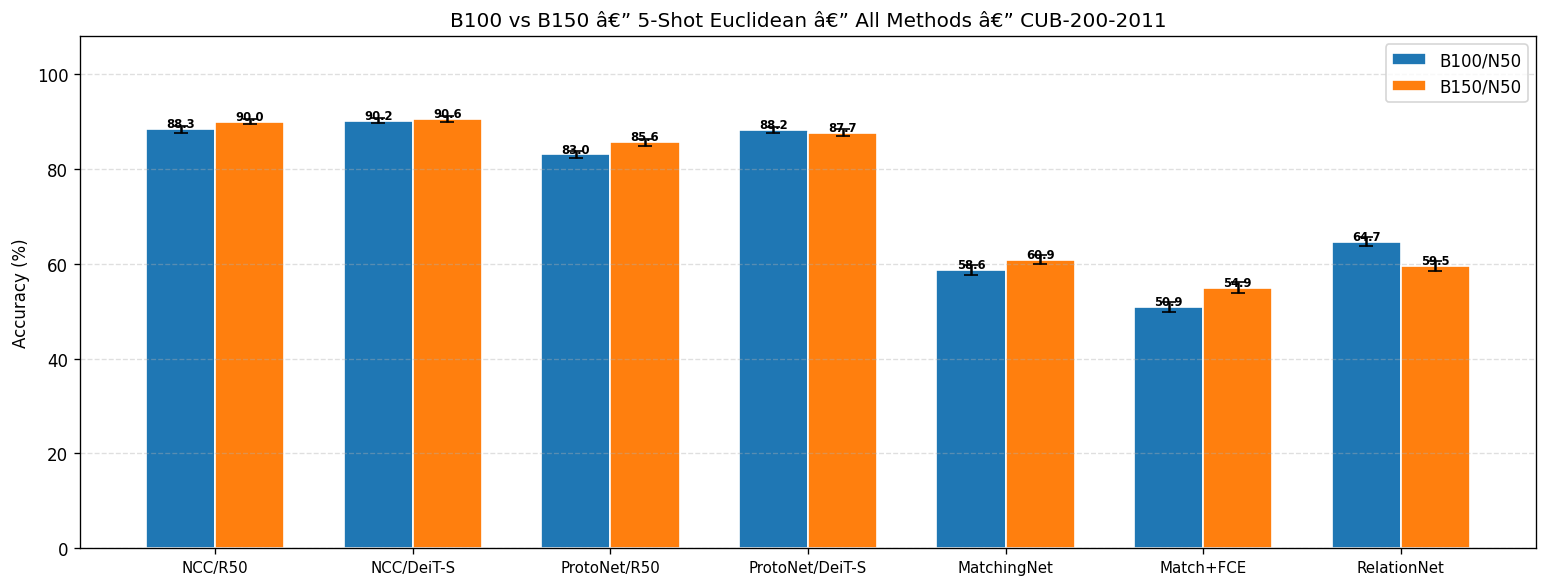

In [16]:
# Side-by-side bar chart: B100 vs B150 for 5-shot Euclidean across all methods
comparison_cfgs=[
    ('NCC/R50',        'b100_ncc_5shot_euc_json',       'b150_ncc_5shot_euc_json'),
    ('NCC/DeiT-S',     'b100_vit_ncc_5shot_euc_json',   'b150_vit_ncc_5shot_euc_json'),
    ('ProtoNet/R50',   'b100_proto_5shot_euc_json',      'b150_proto_5shot_euc_json'),
    ('ProtoNet/DeiT-S','b100_vit_proto_5shot_euc_json',  'b150_vit_proto_5shot_euc_json'),
    ('MatchingNet',    'b100_match_5shot_json',           'b150_match_5shot_json'),
    ('Match+FCE',      'b100_match_fce_5shot_json',       'b150_match_fce_5shot_json'),
    ('RelationNet',    'b100_rel_5shot_json',             'b150_rel_5shot_json'),
]

labels=[c[0] for c in comparison_cfgs]
b100_vals=[acc(c[1]) for c in comparison_cfgs]
b150_vals=[acc(c[2]) for c in comparison_cfgs]
b100_cis =[ci(c[1])  for c in comparison_cfgs]
b150_cis =[ci(c[2])  for c in comparison_cfgs]

x=np.arange(len(labels)); w=0.35
fig,ax=plt.subplots(figsize=(13,5))
bars1=ax.bar(x-w/2, b100_vals, w, label='B100/N50', color='#1f77b4', yerr=b100_cis, capsize=4, edgecolor='white')
bars2=ax.bar(x+w/2, b150_vals, w, label='B150/N50', color='#ff7f0e', yerr=b150_cis, capsize=4, edgecolor='white')
for bars,vals in [(bars1,b100_vals),(bars2,b150_vals)]:
    for bar,v in zip(bars,vals):
        if not np.isnan(v):
            ax.text(bar.get_x()+bar.get_width()/2, v+0.4, f'{v:.1f}', ha='center', fontsize=7, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Accuracy (%)'); ax.set_ylim(0,108)
ax.set_title('B100 vs B150 â€” 5-Shot Euclidean â€” All Methods â€” CUB-200-2011')
ax.legend(fontsize=10); ax.grid(axis='y', linestyle='--', alpha=0.4)

# Print deltas
print('B150 advantage over B100 at 5-shot Euc:')
for lbl,v0,v1 in zip(labels,b100_vals,b150_vals):
    if not (np.isnan(v0) or np.isnan(v1)):
        print(f'  {lbl:<18}: B100={v0:.2f}%  B150={v1:.2f}%  delta={v1-v0:+.2f}pp')

plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_b100_vs_b150_5shot_euc.png', dpi=150)
plt.show()

---
## 3. NCC: ResNet-50 vs DeiT-S (both splits)

,Split,Model,K-Shot,Accuracy(%),95% CI,F1
0,B100,NCC/R50 (Euc),1,72.89,+-1.09,0.7293
1,B100,NCC/R50 (Man),1,72.81,+-1.08,0.7285
2,B100,NCC/DeiT-S (Euc),1,77.23,+-0.97,0.7721
3,B100,NCC/DeiT-S (Man),1,76.86,+-0.98,0.7684
4,B100,NCC/R50 (Euc),3,86.24,+-0.76,0.8625
5,B100,NCC/R50 (Man),3,85.13,+-0.77,0.8514
6,B100,NCC/DeiT-S (Euc),3,88.27,+-0.68,0.8828
7,B100,NCC/DeiT-S (Man),3,88.25,+-0.67,0.8825
8,B100,NCC/R50 (Euc),5,88.33,+-0.68,0.8832
9,B100,NCC/R50 (Man),5,87.19,+-0.73,0.8719


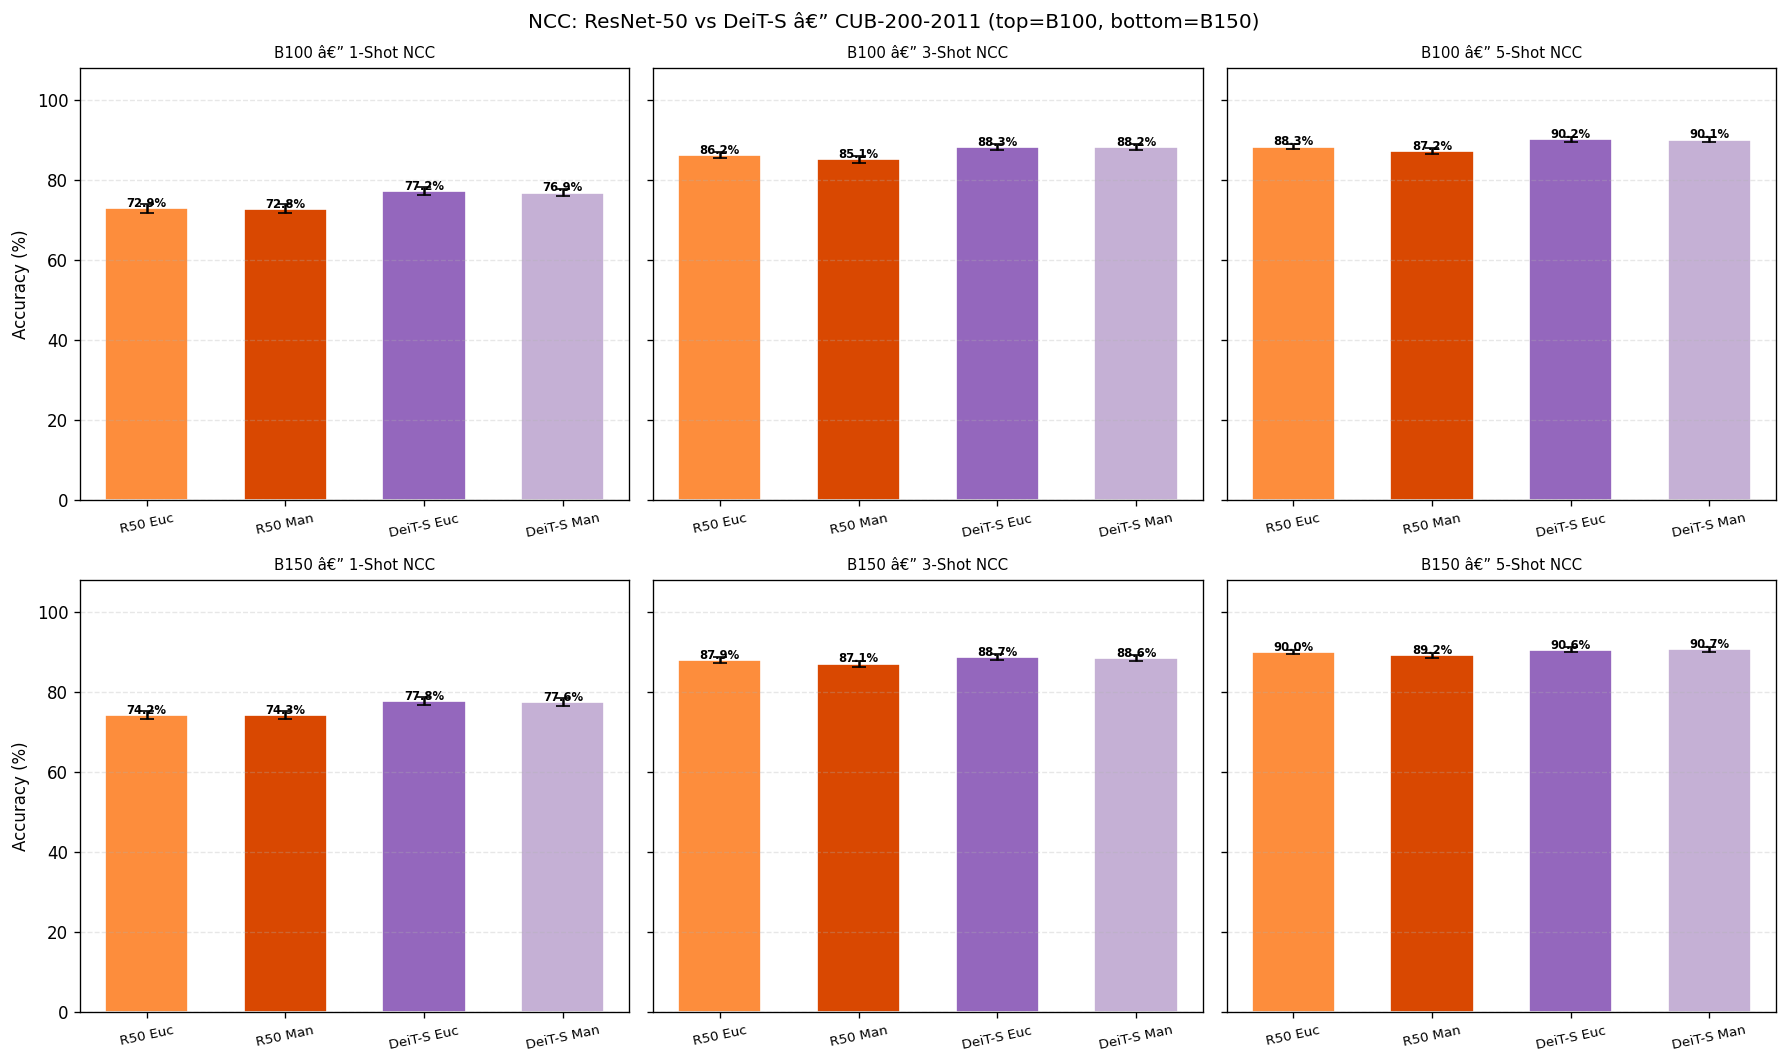

In [17]:
# Table
rows=[]
for split,pfx in [('B100','b100'),('B150','b150')]:
    for s in SHOTS:
        for label,tmpl in [
            ('NCC/R50 (Euc)',   '{p}_ncc_{s}shot_euc_json'),
            ('NCC/R50 (Man)',   '{p}_ncc_{s}shot_man_json'),
            ('NCC/DeiT-S (Euc)','{p}_vit_ncc_{s}shot_euc_json'),
            ('NCC/DeiT-S (Man)','{p}_vit_ncc_{s}shot_man_json'),
        ]:
            k=tmpl.format(p=pfx,s=s); d=R.get(k)
            rows.append({'Split':split,'Model':label,'K-Shot':s,
                         'Accuracy(%)':f'{acc(k):.2f}' if d else 'â€”',
                         '95% CI':f'+-{ci(k):.2f}' if d else 'â€”',
                         'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else 'â€”'})
display(pd.DataFrame(rows))

# Two-row subplot: top=B100, bottom=B150; 3 columns for shots
fig,axes=plt.subplots(2,3,figsize=(15,9),sharey='row')
for row_idx,(split,pfx) in enumerate([('B100','b100'),('B150','b150')]):
    for col_idx,shot in enumerate(SHOTS):
        ax=axes[row_idx][col_idx]
        cfgs=[
            ('R50 Euc',    f'{pfx}_ncc_{shot}shot_euc_json',     '#fd8d3c'),
            ('R50 Man',    f'{pfx}_ncc_{shot}shot_man_json',     '#d94801'),
            ('DeiT-S Euc', f'{pfx}_vit_ncc_{shot}shot_euc_json','#9467bd'),
            ('DeiT-S Man', f'{pfx}_vit_ncc_{shot}shot_man_json','#c5b0d5'),
        ]
        ls_=[c[0] for c in cfgs]
        vs=[acc(c[1]) for c in cfgs]
        es=[ci(c[1])  for c in cfgs]
        cs=[c[2] for c in cfgs]
        bars=ax.bar(ls_,vs,color=cs,edgecolor='white',width=0.6)
        ax.errorbar(range(len(ls_)),vs,yerr=es,fmt='none',color='black',capsize=4)
        for bar,v in zip(bars,vs):
            if not np.isnan(v):
                ax.text(bar.get_x()+bar.get_width()/2, v+0.4, f'{v:.1f}%',
                        ha='center', fontsize=7, fontweight='bold')
        ax.set_title(f'{split} â€” {shot}-Shot NCC', fontsize=9)
        ax.set_ylim(0,108)
        ax.set_ylabel('Accuracy (%)' if col_idx==0 else '')
        ax.tick_params(axis='x', labelrotation=12, labelsize=8)
        ax.grid(axis='y', linestyle='--', alpha=0.3)
fig.suptitle('NCC: ResNet-50 vs DeiT-S â€” CUB-200-2011 (top=B100, bottom=B150)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_ncc_r50_vs_deit_both_splits.png', dpi=150)
plt.show()

---
## 4. ProtoNet: ResNet-50 vs DeiT-S (both splits)

,Split,Model,K-Shot,Accuracy(%),95% CI,F1
0,B100,ProtoNet/R50 (Euc),1,70.03,+-1.06,0.7000
1,B100,ProtoNet/R50 (Man),1,69.17,+-1.09,0.6917
2,B100,ProtoNet/DeiT-S (Euc),1,73.67,+-1.04,0.7368
3,B100,ProtoNet/DeiT-S (Man),1,73.49,+-1.04,0.7349
4,B100,ProtoNet/R50 (Euc),3,80.84,+-0.86,0.8083
5,B100,ProtoNet/R50 (Man),3,79.78,+-0.89,0.7980
6,B100,ProtoNet/DeiT-S (Euc),3,85.48,+-0.75,0.8548
7,B100,ProtoNet/DeiT-S (Man),3,85.45,+-0.75,0.8545
8,B100,ProtoNet/R50 (Euc),5,83.03,+-0.78,0.8300
9,B100,ProtoNet/R50 (Man),5,82.03,+-0.81,0.8202


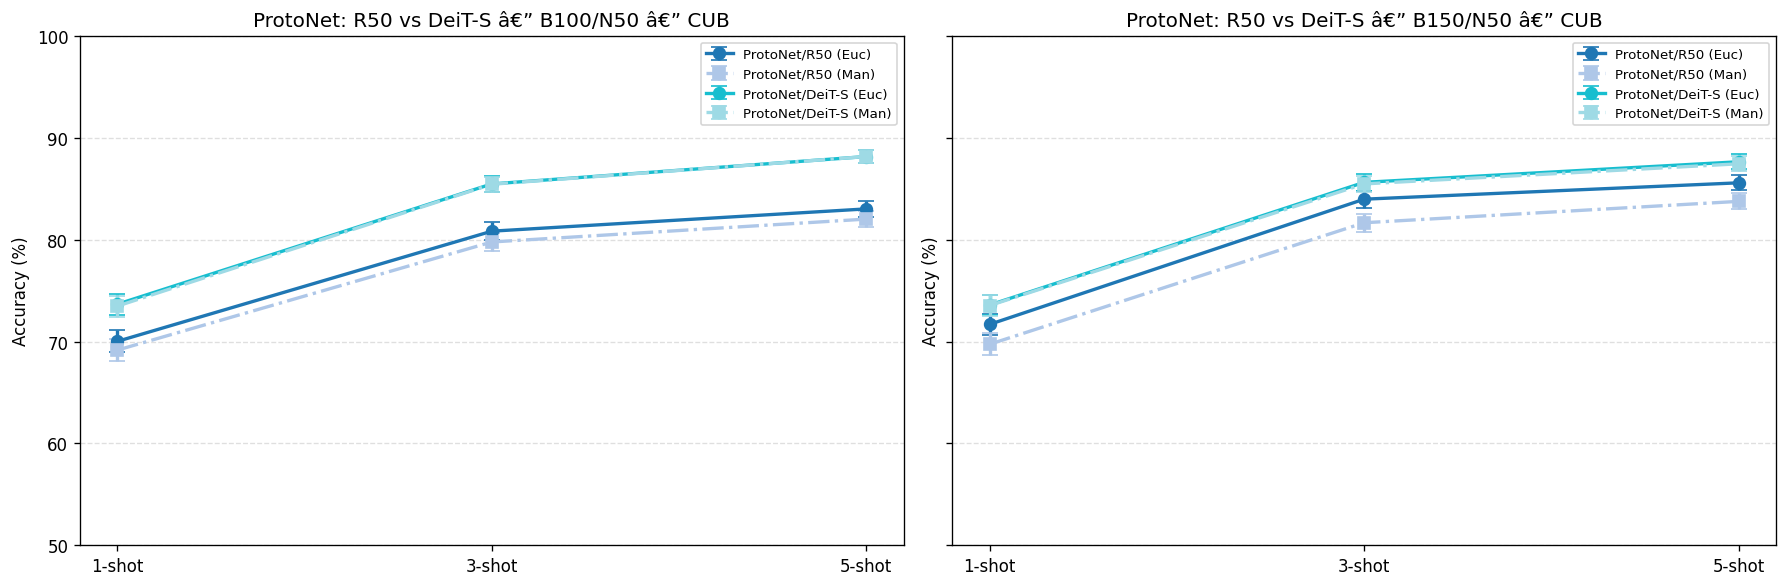

In [18]:
# Table
rows=[]
for split,pfx in [('B100','b100'),('B150','b150')]:
    for s in SHOTS:
        for label,tmpl in [
            ('ProtoNet/R50 (Euc)',   '{p}_proto_{s}shot_euc_json'),
            ('ProtoNet/R50 (Man)',   '{p}_proto_{s}shot_man_json'),
            ('ProtoNet/DeiT-S (Euc)','{p}_vit_proto_{s}shot_euc_json'),
            ('ProtoNet/DeiT-S (Man)','{p}_vit_proto_{s}shot_man_json'),
        ]:
            k=tmpl.format(p=pfx,s=s); d=R.get(k)
            rows.append({'Split':split,'Model':label,'K-Shot':s,
                         'Accuracy(%)':f'{acc(k):.2f}' if d else 'â€”',
                         '95% CI':f'+-{ci(k):.2f}' if d else 'â€”',
                         'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else 'â€”'})
display(pd.DataFrame(rows))

# Line plot with error bars: B100 left, B150 right
fig,axes=plt.subplots(1,2,figsize=(15,5),sharey=True)
style_cfgs=[
    ('ProtoNet/R50 (Euc)',    '{p}_proto_{s}shot_euc_json',    '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',    '{p}_proto_{s}shot_man_json',    '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)','{p}_vit_proto_{s}shot_euc_json','#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)','{p}_vit_proto_{s}shot_man_json','#9edae5','s','-.'),
]
for ax,(split,pfx) in zip(axes,[('B100','b100'),('B150','b150')]):
    for label,tmpl,color,marker,ls in style_cfgs:
        xs,ys,es=zip(*[(s, acc(tmpl.format(p=pfx,s=s)), ci(tmpl.format(p=pfx,s=s))) for s in SHOTS])
        if any(not np.isnan(y) for y in ys):
            ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,
                        linestyle=ls,linewidth=2,markersize=7,capsize=5)
    ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
    ax.set_ylim(50,100); ax.set_ylabel('Accuracy (%)'); ax.legend(fontsize=8)
    ax.set_title(f'ProtoNet: R50 vs DeiT-S â€” {split}/N50 â€” CUB')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_protonet_r50_vs_deit_both_splits.png', dpi=150)
plt.show()

---
## 5. MatchingNet: Vanilla vs FCE (both splits)

FCE adds BiLSTM over support set + attention LSTM for query. Results here use a single distance (no Euc/Man variant â€” MatchingNet uses cosine similarity internally).

,Split,Model,K-Shot,Accuracy(%),95% CI,F1
0,B100,MatchingNet (vanilla),1,48.74,+-1.09,0.4879
1,B100,MatchingNet+FCE,1,47.19,+-1.15,0.4718
2,B100,MatchingNet (vanilla),3,55.62,+-1.01,0.5561
3,B100,MatchingNet+FCE,3,50.45,+-1.02,0.5031
4,B100,MatchingNet (vanilla),5,58.64,+-1.03,0.5862
5,B100,MatchingNet+FCE,5,50.86,+-1.06,0.5070
6,B150,MatchingNet (vanilla),1,53.86,+-1.16,0.5386
7,B150,MatchingNet+FCE,1,51.16,+-1.16,0.5113
8,B150,MatchingNet (vanilla),3,59.80,+-1.11,0.5982
9,B150,MatchingNet+FCE,3,53.61,+-1.10,0.5366


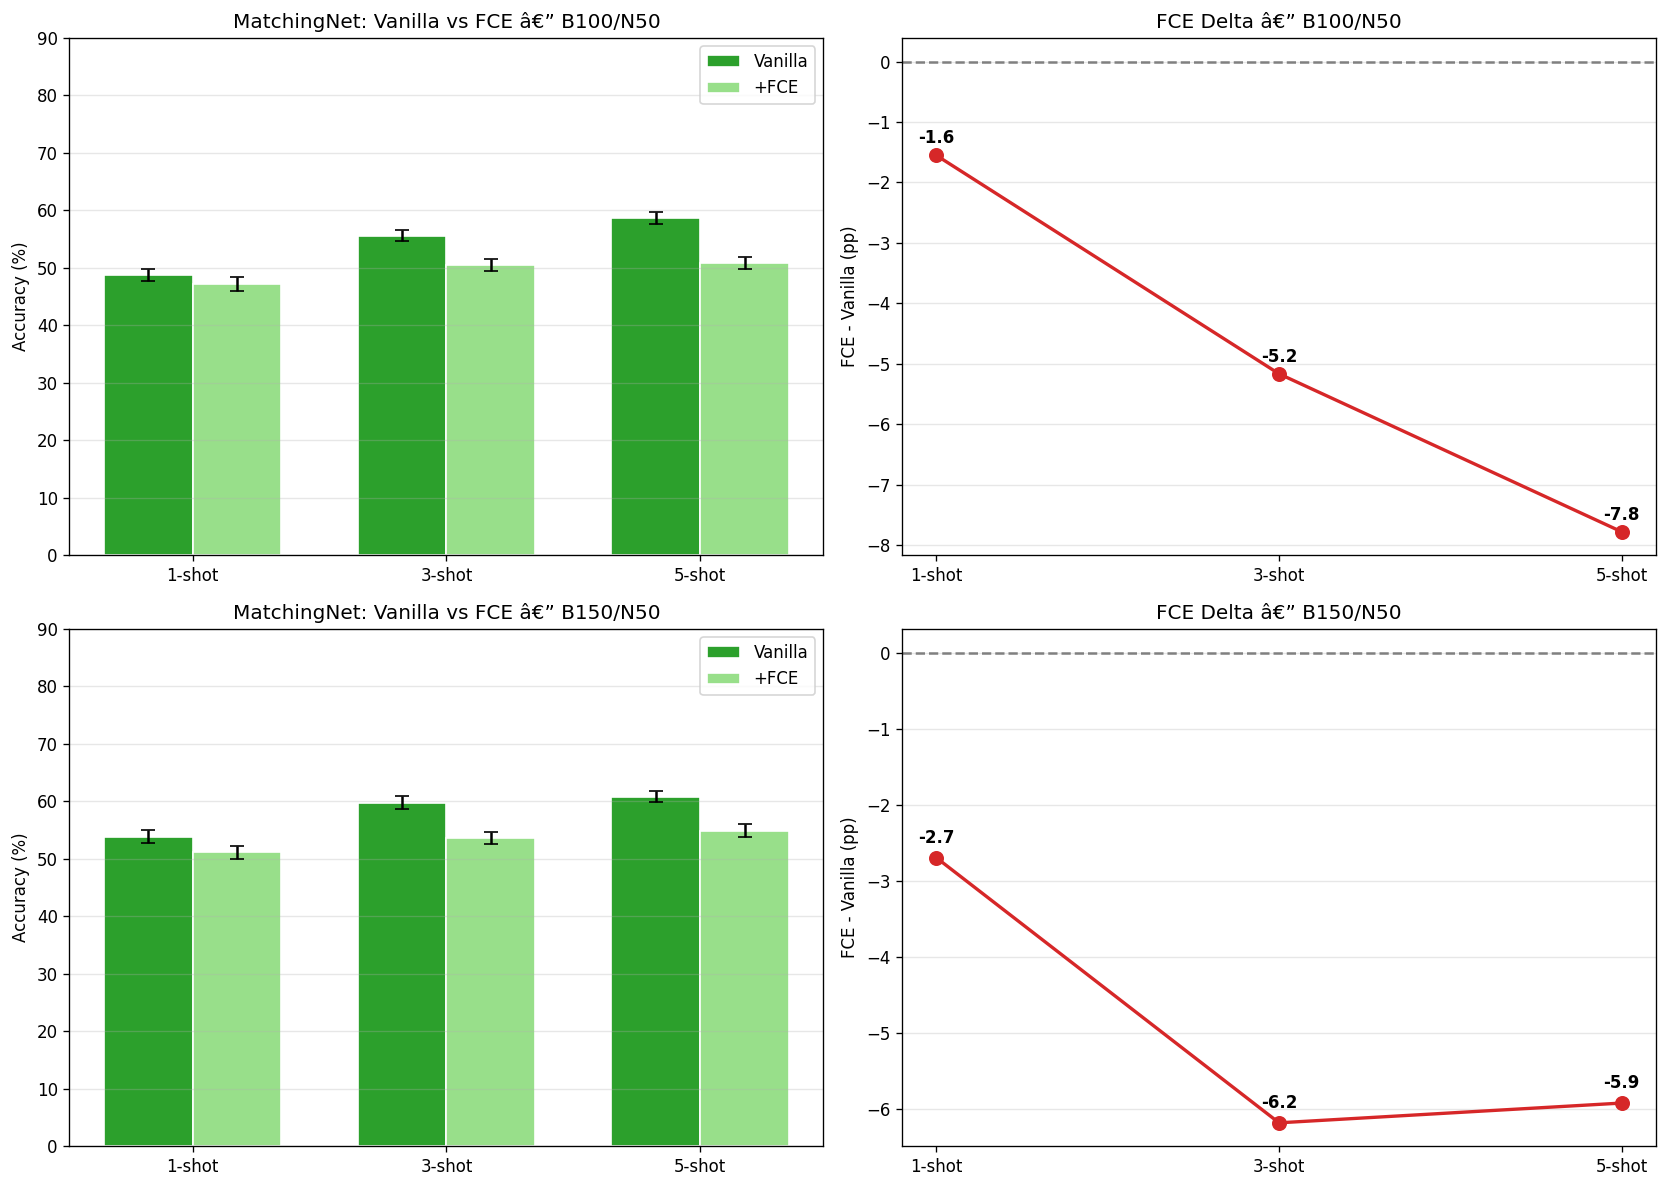

FCE effect (B100): 1-shot: -1.55pp, 3-shot: -5.17pp, 5-shot: -7.78pp
FCE effect (B150): 1-shot: -2.70pp, 3-shot: -6.19pp, 5-shot: -5.93pp


In [19]:
rows=[]
for split,pfx in [('B100','b100'),('B150','b150')]:
    for s in SHOTS:
        for label,tmpl in [
            ('MatchingNet (vanilla)','{p}_match_{s}shot_json'),
            ('MatchingNet+FCE',      '{p}_match_fce_{s}shot_json'),
        ]:
            k=tmpl.format(p=pfx,s=s); d=R.get(k)
            rows.append({'Split':split,'Model':label,'K-Shot':s,
                         'Accuracy(%)':f'{acc(k):.2f}' if d else 'â€”',
                         '95% CI':f'+-{ci(k):.2f}' if d else 'â€”',
                         'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else 'â€”'})
display(pd.DataFrame(rows))

fig,axes=plt.subplots(2,2,figsize=(14,10))
x=np.arange(len(SHOTS)); w=0.35
for row_idx,(split,pfx) in enumerate([('B100','b100'),('B150','b150')]):
    v_a=[acc(f'{pfx}_match_{s}shot_json')     for s in SHOTS]
    f_a=[acc(f'{pfx}_match_fce_{s}shot_json') for s in SHOTS]
    v_c=[ci(f'{pfx}_match_{s}shot_json')      for s in SHOTS]
    f_c=[ci(f'{pfx}_match_fce_{s}shot_json')  for s in SHOTS]

    ax=axes[row_idx][0]
    ax.bar(x-w/2, v_a, w, label='Vanilla', color='#2ca02c', yerr=v_c, capsize=4, edgecolor='white')
    ax.bar(x+w/2, f_a, w, label='+FCE',    color='#98df8a', yerr=f_c, capsize=4, edgecolor='white')
    ax.set_xticks(x); ax.set_xticklabels([f'{s}-shot' for s in SHOTS])
    ax.set_ylim(0,90); ax.set_ylabel('Accuracy (%)')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    ax.set_title(f'MatchingNet: Vanilla vs FCE â€” {split}/N50')

    ax2=axes[row_idx][1]
    deltas=[fa-va for fa,va in zip(f_a,v_a)]
    ax2.plot(SHOTS, deltas, 'o-', color='#d62728', linewidth=2, markersize=8)
    ax2.axhline(0, color='gray', linestyle='--')
    ax2.set_xticks(SHOTS); ax2.set_xticklabels([f'{s}-shot' for s in SHOTS])
    ax2.set_ylabel('FCE - Vanilla (pp)')
    ax2.set_title(f'FCE Delta â€” {split}/N50')
    for s,d in zip(SHOTS,deltas):
        if not np.isnan(d):
            ax2.text(s, d+0.2, f'{d:+.1f}', ha='center', fontsize=10, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_matchingnet_fce_both_splits.png', dpi=150)
plt.show()

for split,pfx in [('B100','b100'),('B150','b150')]:
    deltas=[acc(f'{pfx}_match_fce_{s}shot_json')-acc(f'{pfx}_match_{s}shot_json') for s in SHOTS]
    print(f'FCE effect ({split}): '+', '.join([f'{s}-shot: {d:+.2f}pp' for s,d in zip(SHOTS,deltas)]))

---
## 6. RelationNet (both splits)

RelationNet â€” B100/N50 â€” CUB-200-2011
  1-shot: 55.97% +-1.10  F1=0.5595
  3-shot: 62.85% +-0.99  F1=0.6282
  5-shot: 64.66% +-0.94  F1=0.6461
RelationNet â€” B150/N50 â€” CUB-200-2011
  1-shot: 51.16% +-1.15  F1=0.5114
  3-shot: 57.47% +-0.99  F1=0.5748
  5-shot: 59.54% +-0.99  F1=0.5954


,Split,K-Shot,Accuracy(%),95% CI,F1
0,B100,1,55.97,+-1.10,0.5595
1,B100,3,62.85,+-0.99,0.6282
2,B100,5,64.66,+-0.94,0.6461
3,B150,1,51.16,+-1.15,0.5114
4,B150,3,57.47,+-0.99,0.5748
5,B150,5,59.54,+-0.99,0.5954


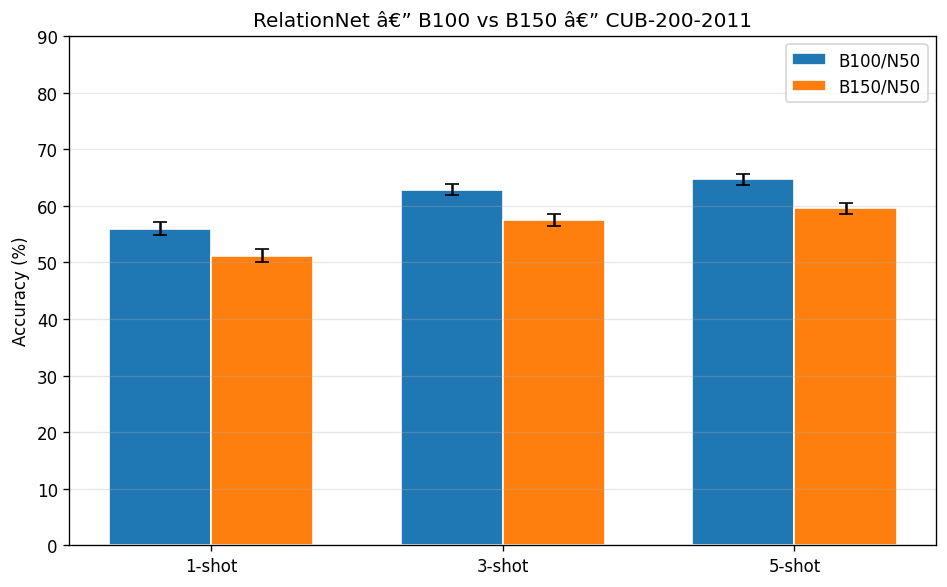

In [20]:
# Print table
rows=[]
for split,pfx in [('B100','b100'),('B150','b150')]:
    print(f'RelationNet â€” {split}/N50 â€” CUB-200-2011')
    for s in SHOTS:
        k=f'{pfx}_rel_{s}shot_json'
        print(f'  {s}-shot: {acc(k):.2f}% +-{ci(k):.2f}  F1={f1(k):.4f}')
        rows.append({'Split':split,'K-Shot':s,
                     'Accuracy(%)':f'{acc(k):.2f}' if R.get(k) else 'â€”',
                     '95% CI':f'+-{ci(k):.2f}' if R.get(k) else 'â€”',
                     'F1':f'{f1(k):.4f}' if R.get(k) and not np.isnan(f1(k)) else 'â€”'})
display(pd.DataFrame(rows))

# Bar chart B100 vs B150
x=np.arange(len(SHOTS)); w=0.35
b100_v=[acc(f'b100_rel_{s}shot_json') for s in SHOTS]
b150_v=[acc(f'b150_rel_{s}shot_json') for s in SHOTS]
b100_c=[ci(f'b100_rel_{s}shot_json')  for s in SHOTS]
b150_c=[ci(f'b150_rel_{s}shot_json')  for s in SHOTS]

fig,ax=plt.subplots(figsize=(8,5))
ax.bar(x-w/2, b100_v, w, label='B100/N50', color='#1f77b4', yerr=b100_c, capsize=4, edgecolor='white')
ax.bar(x+w/2, b150_v, w, label='B150/N50', color='#ff7f0e', yerr=b150_c, capsize=4, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels([f'{s}-shot' for s in SHOTS])
ax.set_ylim(0,90); ax.set_ylabel('Accuracy (%)')
ax.set_title('RelationNet â€” B100 vs B150 â€” CUB-200-2011')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_relationnet_both_splits.png', dpi=150)
plt.show()

---
## 7. K-Shot Trend â€” All Methods

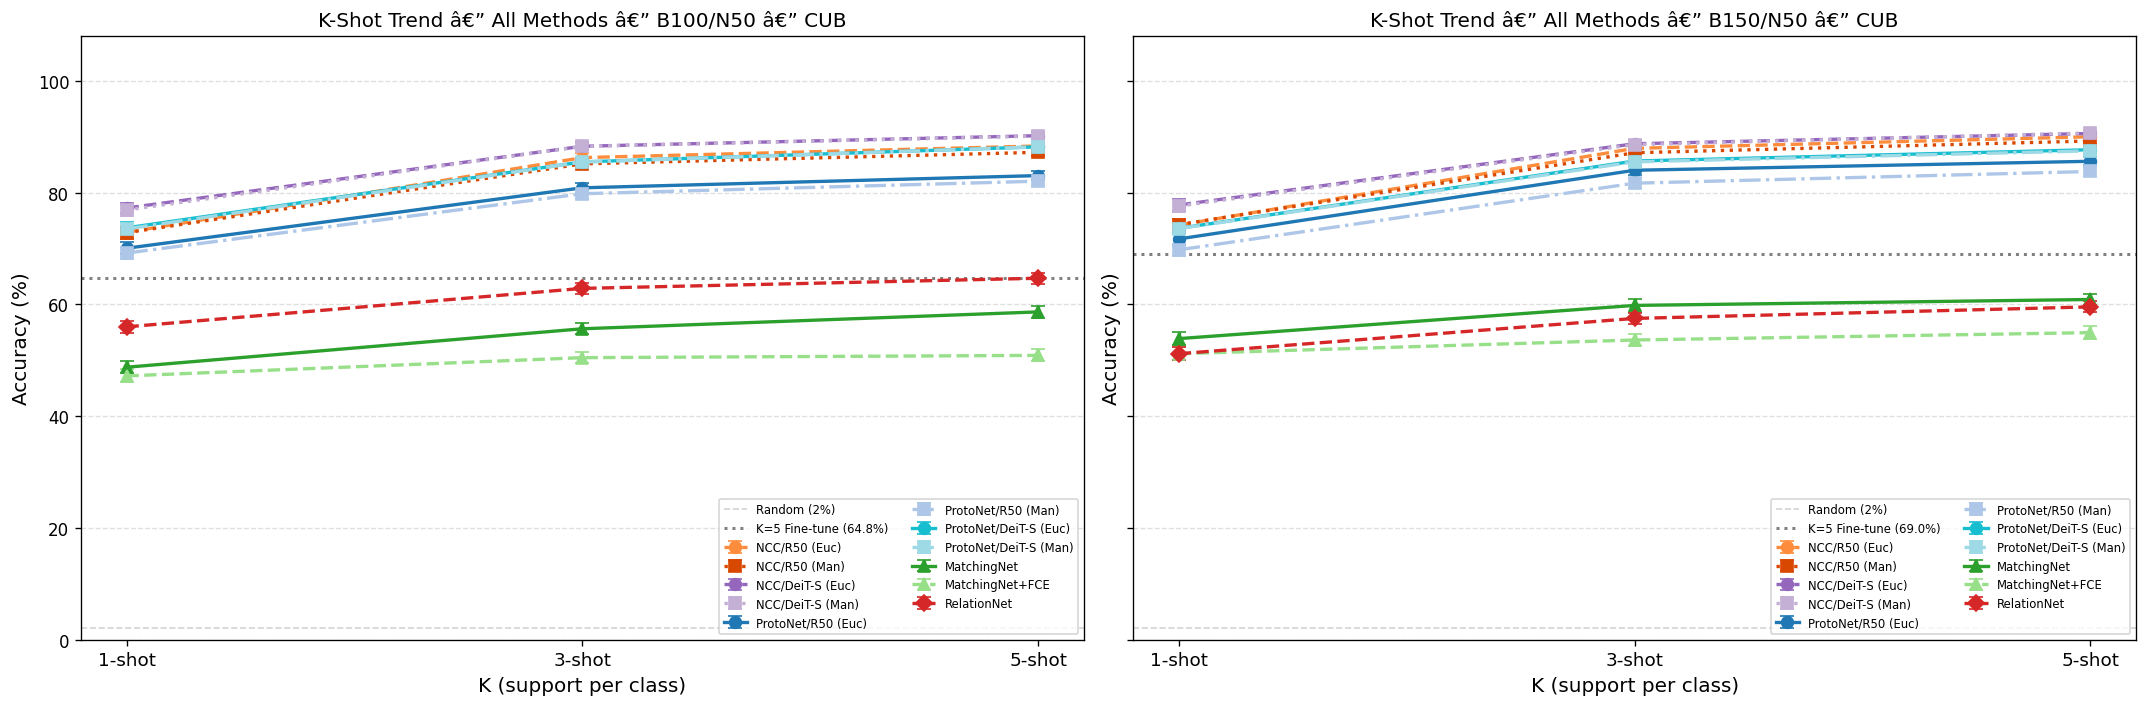

In [21]:
method_configs_b100=[
    ('NCC/R50 (Euc)',          'b100_ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',          'b100_ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',       'b100_vit_ncc_{s}shot_euc_json',    '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',       'b100_vit_ncc_{s}shot_man_json',    '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',     'b100_proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',     'b100_proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)', 'b100_vit_proto_{s}shot_euc_json',  '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)', 'b100_vit_proto_{s}shot_man_json',  '#9edae5','s','-.'),
    ('MatchingNet',            'b100_match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',        'b100_match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',            'b100_rel_{s}shot_json',             '#d62728','D','--'),
]
method_configs_b150=[
    ('NCC/R50 (Euc)',          'b150_ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',          'b150_ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',       'b150_vit_ncc_{s}shot_euc_json',    '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',       'b150_vit_ncc_{s}shot_man_json',    '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',     'b150_proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',     'b150_proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)', 'b150_vit_proto_{s}shot_euc_json',  '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)', 'b150_vit_proto_{s}shot_man_json',  '#9edae5','s','-.'),
    ('MatchingNet',            'b150_match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',        'b150_match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',            'b150_rel_{s}shot_json',             '#d62728','D','--'),
]

fig,axes=plt.subplots(1,2,figsize=(18,6),sharey=True)
for ax,(split,pfx,cfgs) in zip(axes,[
    ('B100','b100',method_configs_b100),
    ('B150','b150',method_configs_b150),
]):
    for label,tmpl,color,marker,ls in cfgs:
        xs,ys,es=[],[],[]
        for s in SHOTS:
            k=tmpl.format(s=s)
            if R.get(k): xs.append(s); ys.append(acc(k)); es.append(ci(k))
        if xs:
            ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,
                        linestyle=ls,linewidth=2,markersize=7,capsize=4)
    ax.axhline(2, color='lightgray', linestyle='--', linewidth=1, label='Random (2%)')
    kd=R.get(f'{pfx}_kshot5_json')
    if kd:
        ref=float(kd.get('test_accuracy',kd.get('accuracy',0)))*100
        ax.axhline(ref, color='gray', linestyle=':', linewidth=1.8, label=f'K=5 Fine-tune ({ref:.1f}%)')
    ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS], fontsize=11)
    ax.set_xlabel('K (support per class)', fontsize=12)
    ax.set_ylabel('Accuracy (%)', fontsize=12)
    ax.set_ylim(0,108); ax.legend(loc='lower right', fontsize=7, ncol=2)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_title(f'K-Shot Trend â€” All Methods â€” {split}/N50 â€” CUB')

plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_kshot_all_both_splits.png', dpi=150)
plt.show()

---
## 8. Per-Class Accuracy Heatmap (Top-15 Hardest Novel Classes)

CUB has 50 novel classes â€” we show only the 15 hardest (lowest mean accuracy across all methods) to keep the heatmap readable. Separate heatmaps for B100 and B150 per shot.

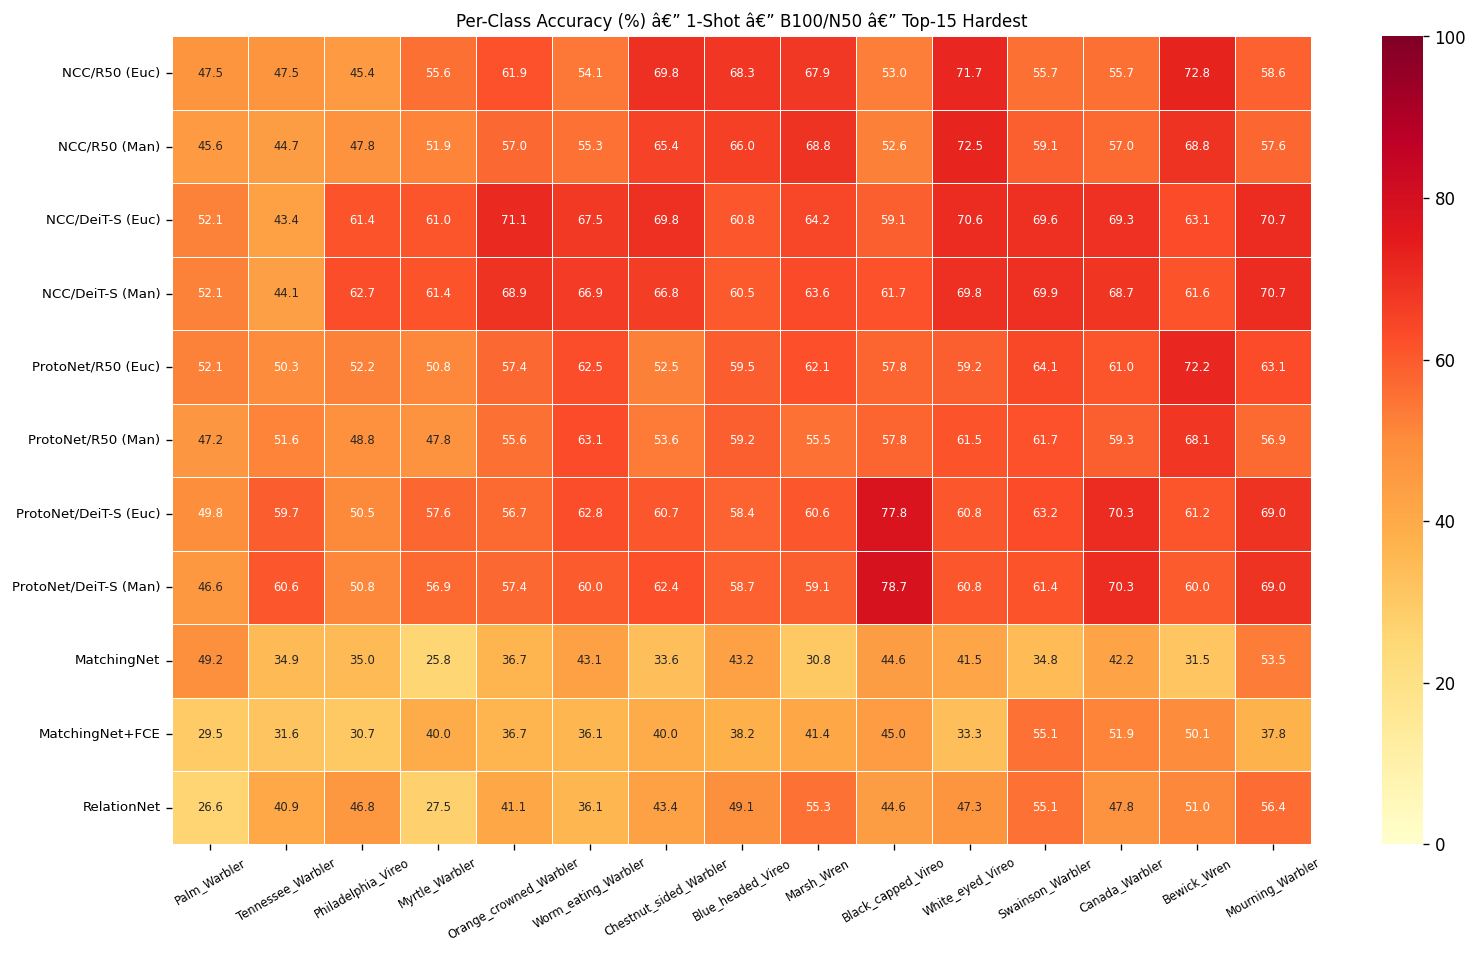

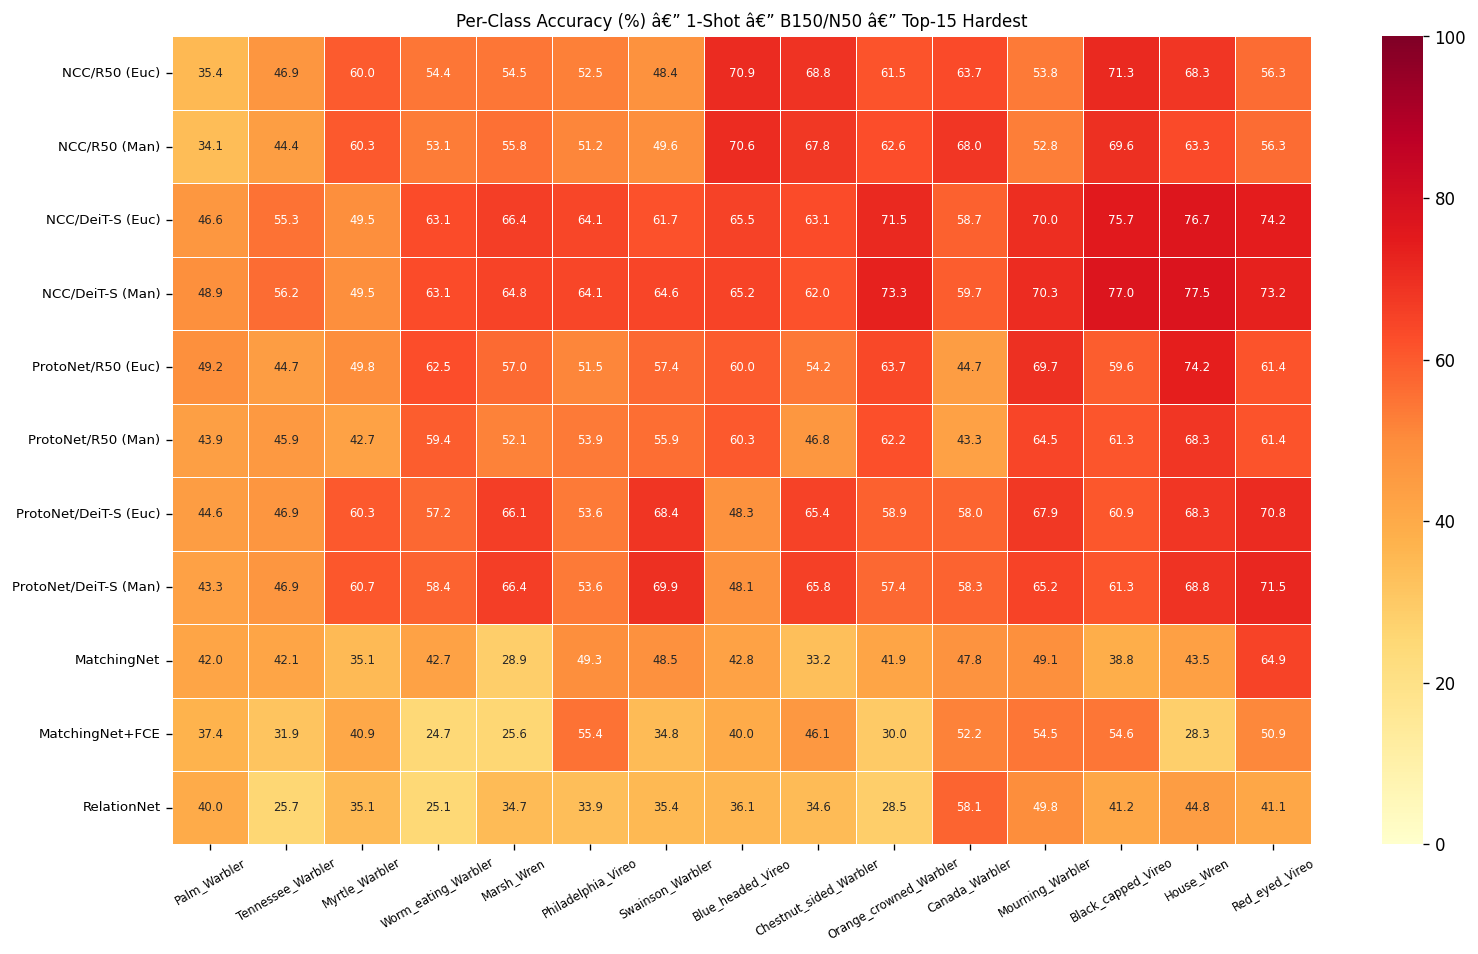

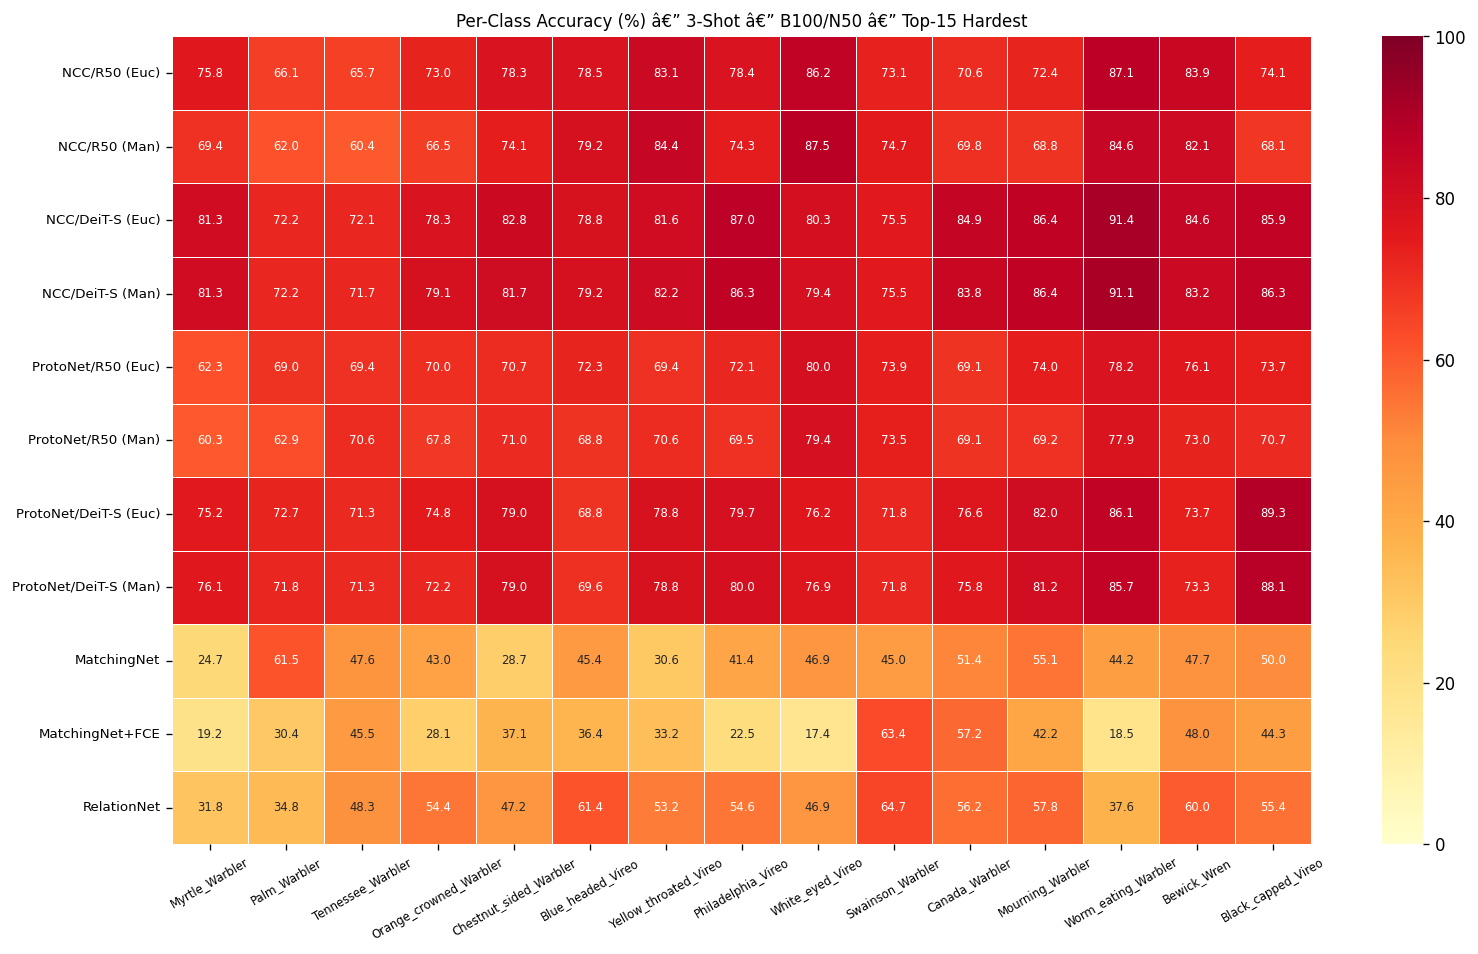

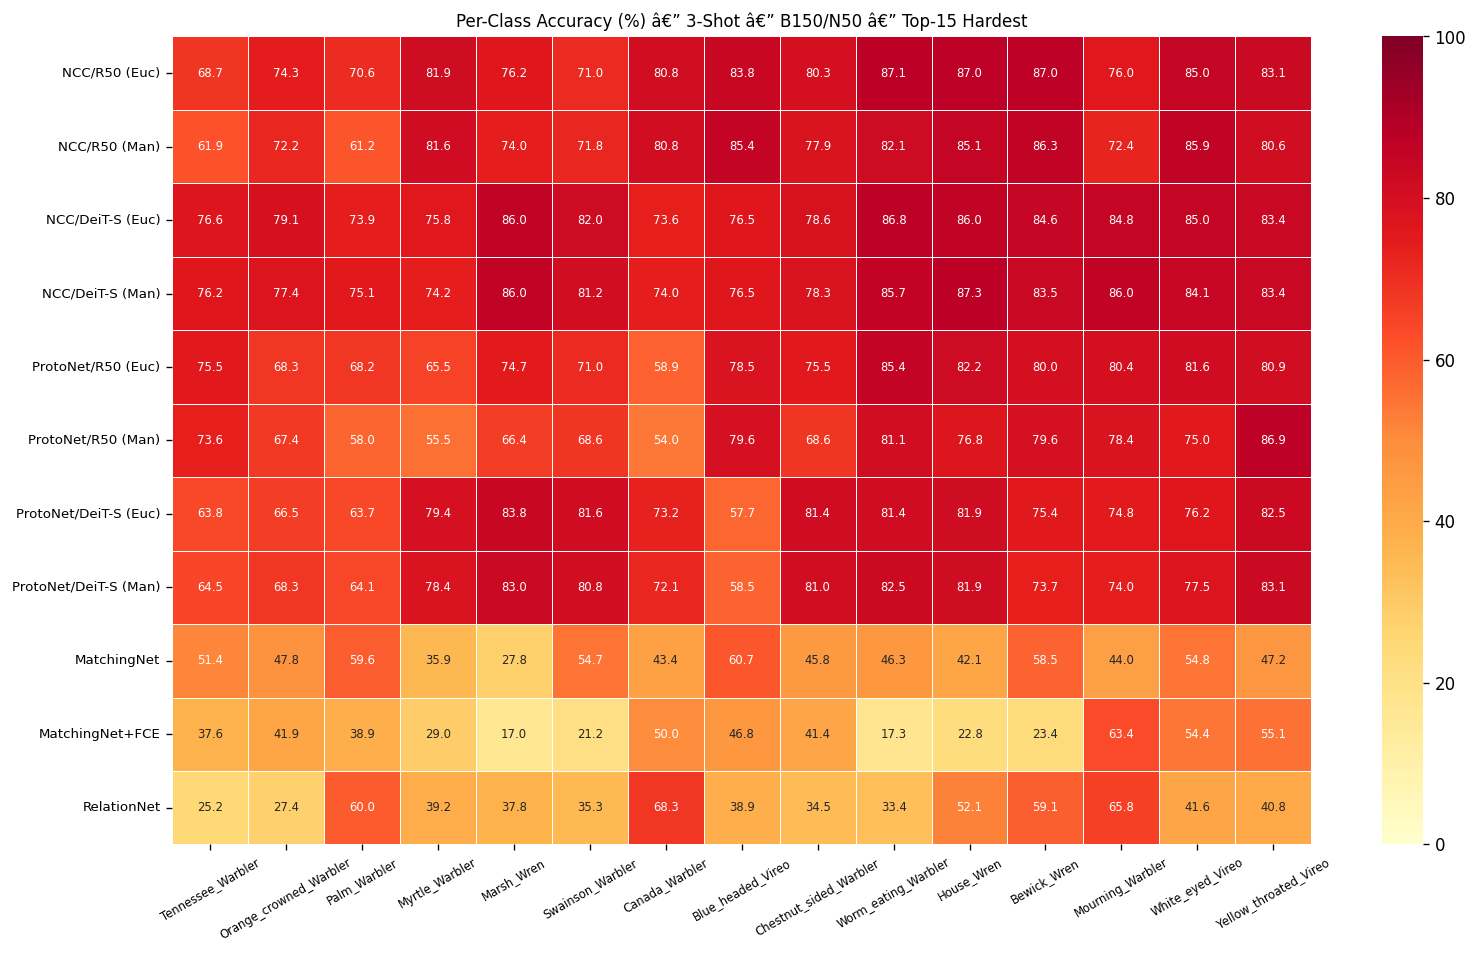

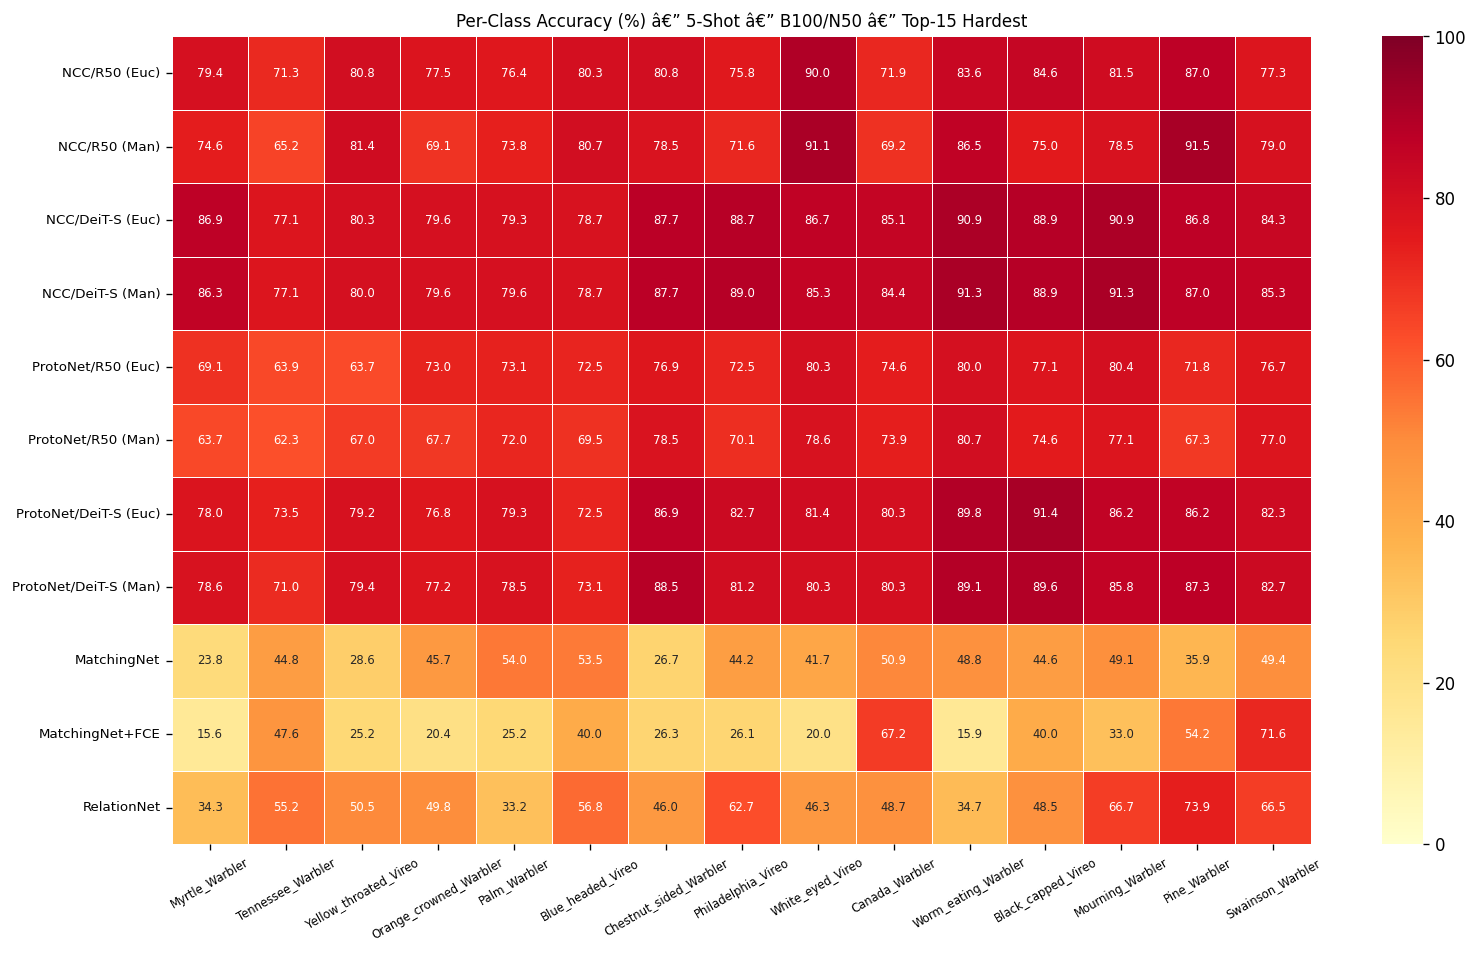

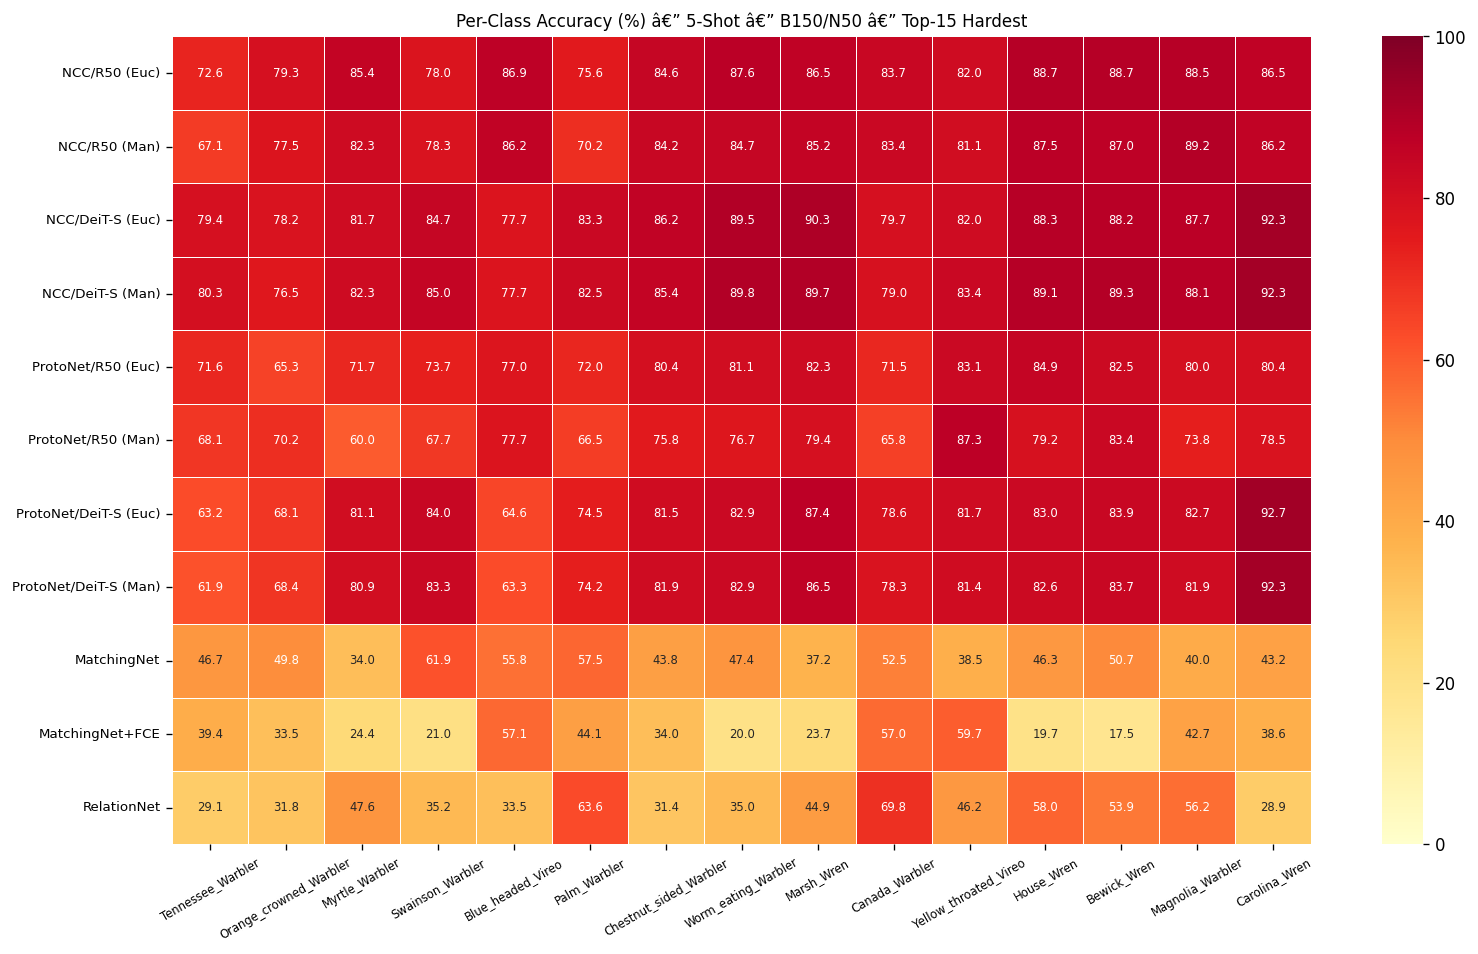

In [22]:
method_configs_heatmap=[
    ('NCC/R50 (Euc)',          'b{sp}_ncc_{s}shot_euc_json'),
    ('NCC/R50 (Man)',          'b{sp}_ncc_{s}shot_man_json'),
    ('NCC/DeiT-S (Euc)',       'b{sp}_vit_ncc_{s}shot_euc_json'),
    ('NCC/DeiT-S (Man)',       'b{sp}_vit_ncc_{s}shot_man_json'),
    ('ProtoNet/R50 (Euc)',     'b{sp}_proto_{s}shot_euc_json'),
    ('ProtoNet/R50 (Man)',     'b{sp}_proto_{s}shot_man_json'),
    ('ProtoNet/DeiT-S (Euc)', 'b{sp}_vit_proto_{s}shot_euc_json'),
    ('ProtoNet/DeiT-S (Man)', 'b{sp}_vit_proto_{s}shot_man_json'),
    ('MatchingNet',            'b{sp}_match_{s}shot_json'),
    ('MatchingNet+FCE',        'b{sp}_match_fce_{s}shot_json'),
    ('RelationNet',            'b{sp}_rel_{s}shot_json'),
]

TOP_HARD=15

for shot in SHOTS:
    for sp_label,sp in [('B100','100'),('B150','150')]:
        # Gather all per-class data
        all_pca={}
        for name,tmpl in method_configs_heatmap:
            k=tmpl.format(sp=sp,s=shot)
            d=R.get(k)
            if d and 'per_class_accuracy_pct' in d:
                all_pca[name]=d['per_class_accuracy_pct']

        if not all_pca: print(f'[{shot}-shot {sp_label}] No per-class data.'); continue

        # Get union of all classes present, compute mean across methods
        all_classes=set()
        for pca in all_pca.values(): all_classes.update(pca.keys())
        all_classes=sorted(all_classes)

        mean_by_class={}
        for cls in all_classes:
            vals=[pca[cls] for pca in all_pca.values() if cls in pca]
            mean_by_class[cls]=np.nanmean(vals) if vals else float('nan')

        # Bottom-15 (hardest)
        sorted_cls=sorted(mean_by_class, key=lambda c: mean_by_class[c])
        hard_classes=sorted_cls[:TOP_HARD]

        row_labels=list(all_pca.keys())
        matrix=np.array(
            [[all_pca[name].get(cls, float('nan')) for cls in hard_classes]
             for name in row_labels],
            dtype=float
        )

        # Shorten class names for display
        short_cls=[c[:22] for c in hard_classes]

        fig,ax=plt.subplots(figsize=(max(12,TOP_HARD*0.9), len(row_labels)*0.55+2))
        sns.heatmap(matrix, annot=True, fmt='.1f', cmap='YlOrRd',
                    xticklabels=short_cls, yticklabels=row_labels,
                    ax=ax, vmin=0, vmax=100, linewidths=0.5, linecolor='white',
                    annot_kws={'size':7}, mask=np.isnan(matrix))
        ax.set_title(f'Per-Class Accuracy (%) â€” {shot}-Shot â€” {sp_label}/N50 â€” Top-{TOP_HARD} Hardest', fontsize=10)
        ax.tick_params(axis='x', labelrotation=30, labelsize=7)
        ax.tick_params(axis='y', labelrotation=0, labelsize=8)
        plt.tight_layout()
        plt.savefig(f'{ANALYSIS}/cub_perclass_heatmap_{shot}shot_{sp_label.lower()}.png', dpi=150)
        plt.show()

---
## 9. Backbone Ablation: DeiT-S vs ResNet-50

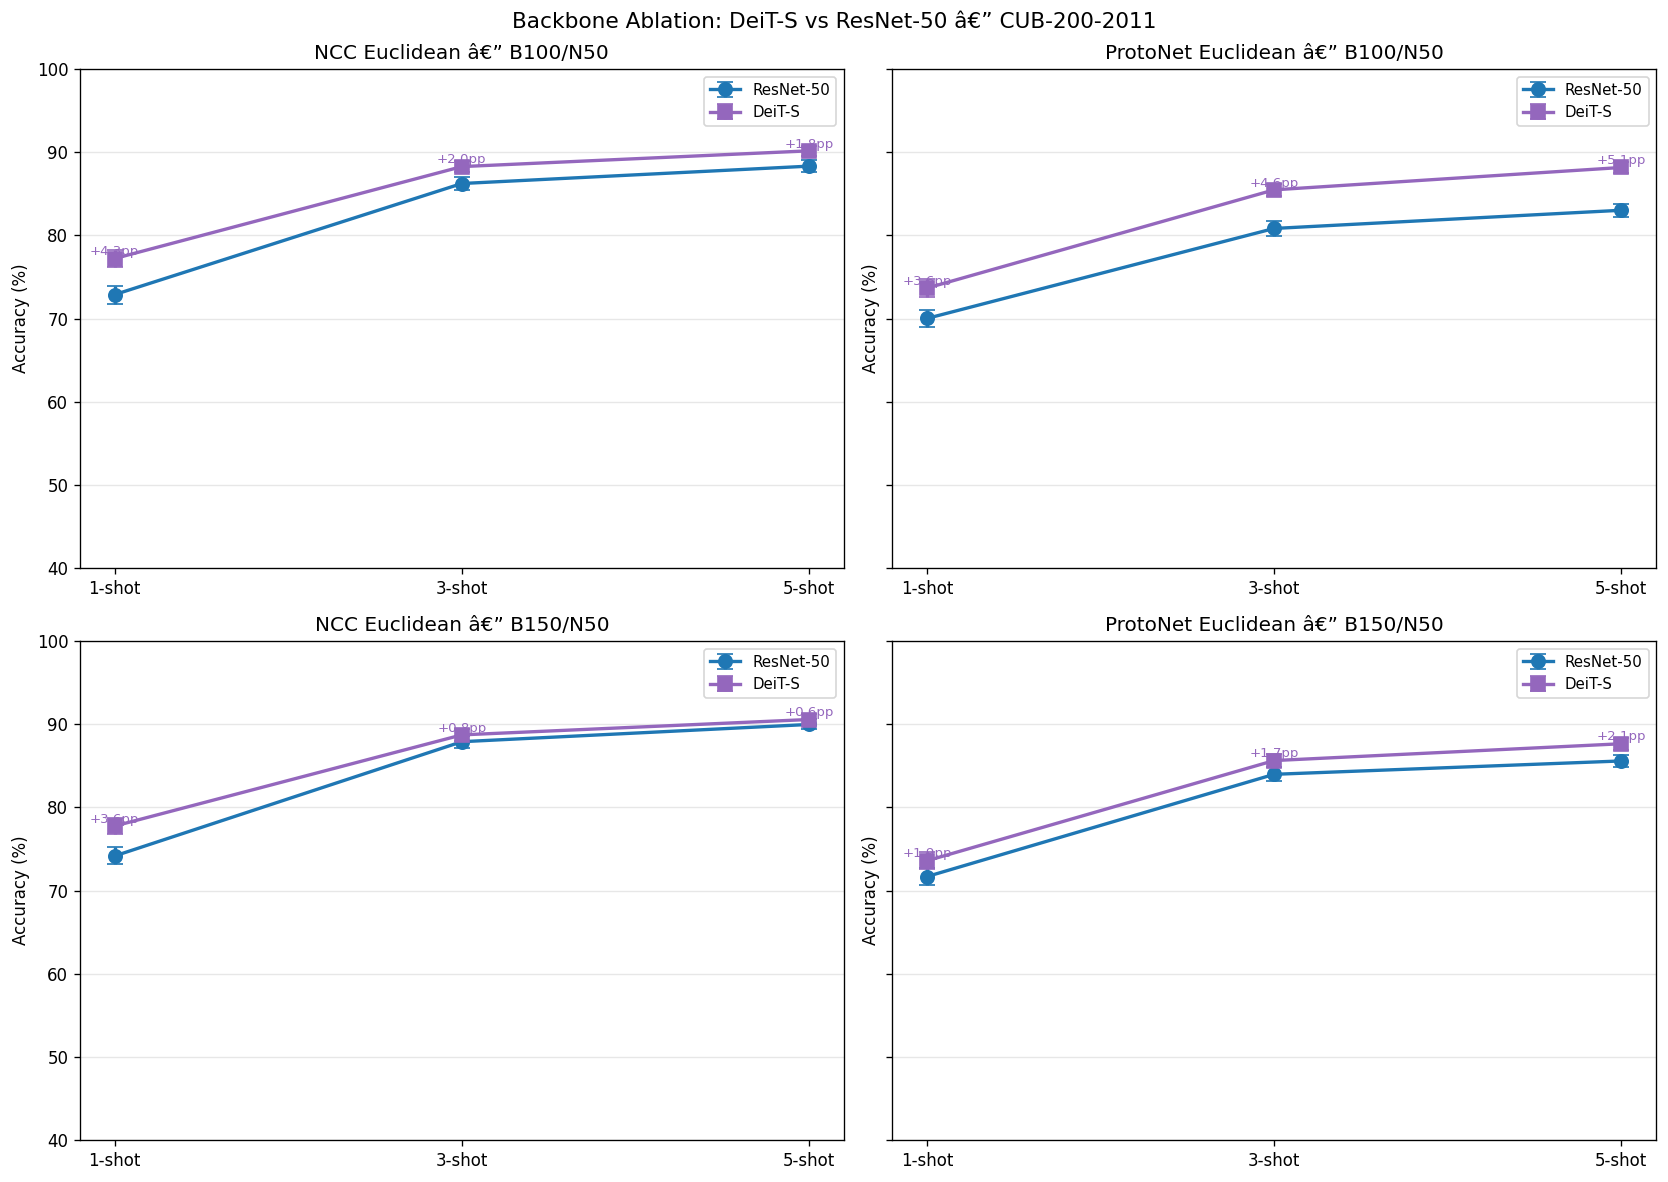

In [23]:
# 2x2 grid: NCC and ProtoNet x B100 and B150
fig,axes=plt.subplots(2,2,figsize=(14,10),sharey='row')
ablation_algos=[
    ('NCC',      'b{sp}_ncc_{s}shot_euc_json',       'b{sp}_vit_ncc_{s}shot_euc_json',      'NCC Euclidean'),
    ('ProtoNet', 'b{sp}_proto_{s}shot_euc_json',      'b{sp}_vit_proto_{s}shot_euc_json',    'ProtoNet Euclidean'),
]
for col_idx,(algo,r50t,vitr,title) in enumerate(ablation_algos):
    for row_idx,(sp_label,sp) in enumerate([('B100','100'),('B150','150')]):
        ax=axes[row_idx][col_idx]
        r50a=[acc(r50t.format(sp=sp,s=s)) for s in SHOTS]
        vita=[acc(vitr.format(sp=sp,s=s)) for s in SHOTS]
        r50c=[ci(r50t.format(sp=sp,s=s))  for s in SHOTS]
        vitc=[ci(vitr.format(sp=sp,s=s))  for s in SHOTS]
        ax.errorbar(SHOTS,r50a,yerr=r50c,label='ResNet-50',color='#1f77b4',marker='o',
                    linewidth=2,markersize=8,capsize=5)
        ax.errorbar(SHOTS,vita,yerr=vitc,label='DeiT-S',   color='#9467bd',marker='s',
                    linewidth=2,markersize=8,capsize=5)
        for s,r,v in zip(SHOTS,r50a,vita):
            if not (np.isnan(r) or np.isnan(v)):
                ax.annotate(f'{v-r:+.1f}pp',(s,max(r,v)+0.4),ha='center',fontsize=8,color='#9467bd')
        ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
        ax.set_ylim(40,100); ax.set_ylabel('Accuracy (%)')
        ax.set_title(f'{title} â€” {sp_label}/N50')
        ax.legend(fontsize=9); ax.grid(axis='y',alpha=0.3)
fig.suptitle('Backbone Ablation: DeiT-S vs ResNet-50 â€” CUB-200-2011', fontsize=13)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_backbone_ablation.png', dpi=150)
plt.show()

---
## 10. NCC vs ProtoNet (Episodic Training Benefit)

NCC uses the frozen backbone directly; ProtoNet uses episodic meta-training. This comparison isolates the benefit of episodic training on CUB's fine-grained 50-class novel set.

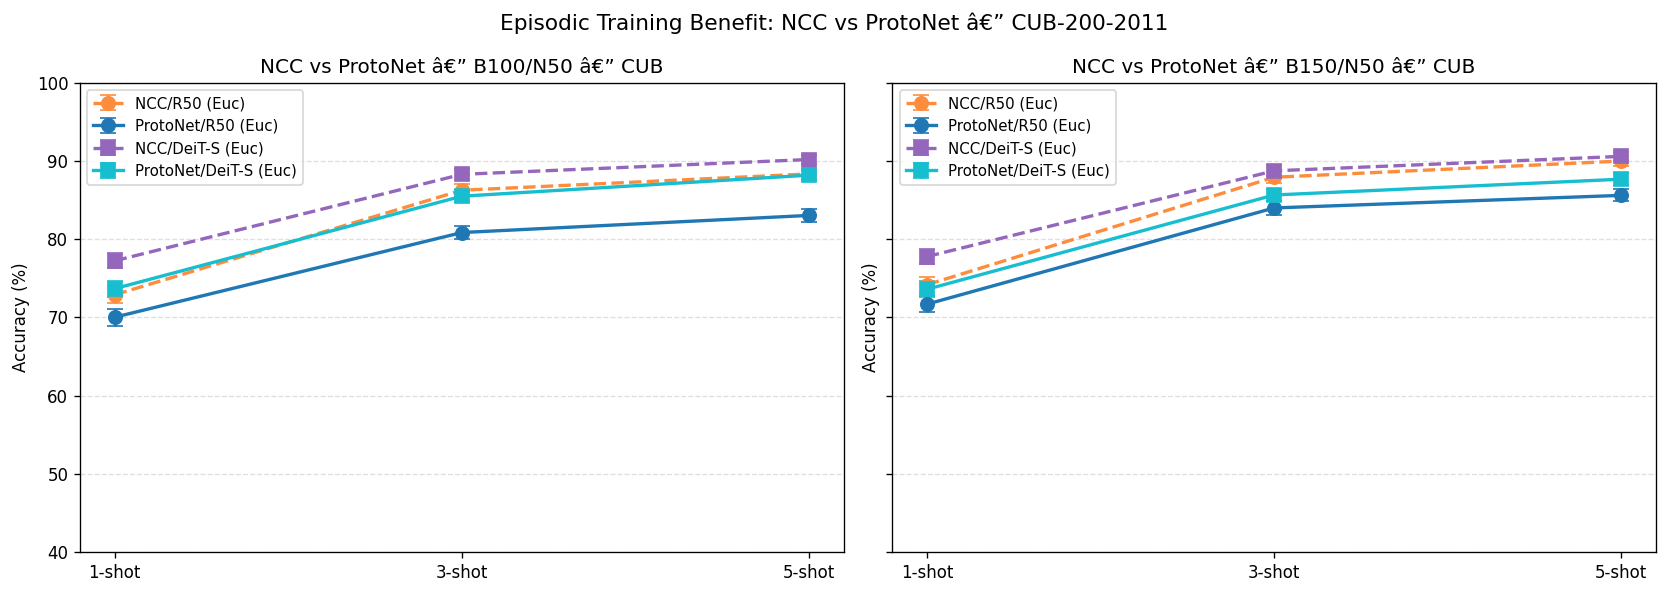

ProtoNet vs NCC lift (Euclidean, R50):
  B100:
    1-shot: NCC=72.89%  ProtoNet=70.03%  delta=-2.87pp
    3-shot: NCC=86.24%  ProtoNet=80.84%  delta=-5.40pp
    5-shot: NCC=88.33%  ProtoNet=83.03%  delta=-5.30pp
  B150:
    1-shot: NCC=74.17%  ProtoNet=71.69%  delta=-2.48pp
    3-shot: NCC=87.90%  ProtoNet=83.98%  delta=-3.92pp
    5-shot: NCC=89.97%  ProtoNet=85.59%  delta=-4.39pp


In [24]:
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
compare_cfgs=[
    ('NCC/R50 (Euc)',          'b{sp}_ncc_{s}shot_euc_json',     '#fd8d3c','o','--'),
    ('ProtoNet/R50 (Euc)',     'b{sp}_proto_{s}shot_euc_json',   '#1f77b4','o','-'),
    ('NCC/DeiT-S (Euc)',       'b{sp}_vit_ncc_{s}shot_euc_json','#9467bd','s','--'),
    ('ProtoNet/DeiT-S (Euc)', 'b{sp}_vit_proto_{s}shot_euc_json','#17becf','s','-'),
]
for ax,(sp_label,sp) in zip(axes,[('B100','100'),('B150','150')]):
    for label,tmpl,color,marker,ls in compare_cfgs:
        xs,ys,es=[],[],[]
        for s in SHOTS:
            k=tmpl.format(sp=sp,s=s)
            if R.get(k): xs.append(s); ys.append(acc(k)); es.append(ci(k))
        if xs:
            ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,
                        linestyle=ls,linewidth=2,markersize=8,capsize=5)
    ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
    ax.set_ylim(40,100); ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'NCC vs ProtoNet â€” {sp_label}/N50 â€” CUB')
    ax.legend(fontsize=9); ax.grid(axis='y',linestyle='--',alpha=0.4)

fig.suptitle('Episodic Training Benefit: NCC vs ProtoNet â€” CUB-200-2011', fontsize=13)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/cub_ncc_vs_protonet.png', dpi=150)
plt.show()

print('ProtoNet vs NCC lift (Euclidean, R50):')
for sp_label,sp in [('B100','100'),('B150','150')]:
    print(f'  {sp_label}:')
    for s in SHOTS:
        ncc_a=acc(f'b{sp}_ncc_{s}shot_euc_json')
        pn_a =acc(f'b{sp}_proto_{s}shot_euc_json')
        print(f'    {s}-shot: NCC={ncc_a:.2f}%  ProtoNet={pn_a:.2f}%  delta={pn_a-ncc_a:+.2f}pp')

---
## 11. Full Summary Table

In [25]:
rows=[]
all_methods=[
    ('NCC/R50 (Euc)',          'b{sp}_ncc_{s}shot_euc_json'),
    ('NCC/R50 (Man)',          'b{sp}_ncc_{s}shot_man_json'),
    ('NCC/DeiT-S (Euc)',       'b{sp}_vit_ncc_{s}shot_euc_json'),
    ('NCC/DeiT-S (Man)',       'b{sp}_vit_ncc_{s}shot_man_json'),
    ('ProtoNet/R50 (Euc)',     'b{sp}_proto_{s}shot_euc_json'),
    ('ProtoNet/R50 (Man)',     'b{sp}_proto_{s}shot_man_json'),
    ('ProtoNet/DeiT-S (Euc)', 'b{sp}_vit_proto_{s}shot_euc_json'),
    ('ProtoNet/DeiT-S (Man)', 'b{sp}_vit_proto_{s}shot_man_json'),
    ('MatchingNet',            'b{sp}_match_{s}shot_json'),
    ('MatchingNet+FCE',        'b{sp}_match_fce_{s}shot_json'),
    ('RelationNet',            'b{sp}_rel_{s}shot_json'),
]
for sp_label,sp in [('B100','100'),('B150','150')]:
    for s in SHOTS:
        for label,tmpl in all_methods:
            k=tmpl.format(sp=sp,s=s); d=R.get(k)
            rows.append({
                'Split':sp_label, 'Method':label, 'K-Shot':s,
                'Accuracy(%)': f'{acc(k):.2f}' if d else 'â€”',
                '95% CI':      f'+-{ci(k):.2f}' if d else 'â€”',
                'F1':          f'{f1(k):.4f}'   if d and not np.isnan(f1(k)) else 'â€”',
                'Precision':   f"{float(d['macro_precision']):.4f}" if d and d.get('macro_precision') else 'â€”',
                'Recall':      f"{float(d['macro_recall']):.4f}"    if d and d.get('macro_recall')    else 'â€”',
                'AUC':         f"{float(d['auc_ovr']):.4f}"         if d and d.get('auc_ovr')         else 'â€”',
            })

df_s=pd.DataFrame(rows); df_s.index=range(1,len(df_s)+1)
display(df_s)
out_csv=f'{ANALYSIS}/cub_summary.csv'
df_s.to_csv(out_csv)
print(f'Saved to {out_csv}')

,Split,Method,K-Shot,Accuracy(%),95% CI,F1,Precision,Recall,AUC
1,B100,NCC/R50 (Euc),1,72.89,+-1.09,0.7293,0.7299,0.7289,0.9305
2,B100,NCC/R50 (Man),1,72.81,+-1.08,0.7285,0.7292,0.7281,0.8903
3,B100,NCC/DeiT-S (Euc),1,77.23,+-0.97,0.7721,0.7721,0.7723,0.9500
4,B100,NCC/DeiT-S (Man),1,76.86,+-0.98,0.7684,0.7684,0.7686,0.9387
5,B100,ProtoNet/R50 (Euc),1,70.03,+-1.06,0.7000,0.7001,0.7003,0.9223
...,...,...,...,...,...,...,...,...,...
62,B150,ProtoNet/DeiT-S (Euc),5,87.65,+-0.73,0.8766,0.8767,0.8765,0.9840
63,B150,ProtoNet/DeiT-S (Man),5,87.45,+-0.74,0.8746,0.8746,0.8745,0.9810
64,B150,MatchingNet,5,60.86,+-1.00,0.6085,0.6087,0.6086,0.8790
65,B150,MatchingNet+FCE,5,54.93,+-1.17,0.5493,0.5611,0.5493,0.8233


Saved to .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results\cub\analysis/cub_summary.csv


---
## 12. Key Insights

In [26]:
print('='*70)
print('  KEY FINDINGS â€” CUB-200-2011 (B100/N50 and B150/N50)')
print('='*70)

print('\n1. DeiT-S vs ResNet-50 lift (NCC + ProtoNet, Euclidean):')
for sp_label,sp in [('B100','100'),('B150','150')]:
    print(f'  {sp_label}:')
    for algo,r50t,vitr in [
        ('NCC',     'b{sp}_ncc_{s}shot_euc_json',      'b{sp}_vit_ncc_{s}shot_euc_json'),
        ('ProtoNet','b{sp}_proto_{s}shot_euc_json',     'b{sp}_vit_proto_{s}shot_euc_json'),
    ]:
        for s in SHOTS:
            r=acc(r50t.format(sp=sp,s=s)); v=acc(vitr.format(sp=sp,s=s))
            print(f'    {algo} {s}-shot: DeiT-S={v:.2f}%  R50={r:.2f}%  delta={v-r:+.2f}pp')

print('\n2. B150 vs B100 advantage (5-shot Euc NCC/R50):')
for s in SHOTS:
    b100_a=acc(f'b100_ncc_{s}shot_euc_json')
    b150_a=acc(f'b150_ncc_{s}shot_euc_json')
    print(f'  NCC/R50 {s}-shot: B100={b100_a:.2f}%  B150={b150_a:.2f}%  delta={b150_a-b100_a:+.2f}pp')

print('\n3. MatchingNet FCE effect (B100 and B150):')
for sp_label,sp in [('B100','100'),('B150','150')]:
    for s in SHOTS:
        v=acc(f'b{sp}_match_{s}shot_json'); fce=acc(f'b{sp}_match_fce_{s}shot_json')
        print(f'  {sp_label} {s}-shot: FCE={fce:.2f}%  vanilla={v:.2f}%  delta={fce-v:+.2f}pp')

print('\n4. Ranking at 5-shot (B100, best of Euc/Man):')
ranking_b100=[
    ('NCC/DeiT-S',      'b100_vit_ncc_5shot_euc_json'),
    ('ProtoNet/DeiT-S', 'b100_vit_proto_5shot_euc_json'),
    ('NCC/R50',         'b100_ncc_5shot_euc_json'),
    ('ProtoNet/R50',    'b100_proto_5shot_euc_json'),
    ('MatchingNet',     'b100_match_5shot_json'),
    ('MatchingNet+FCE', 'b100_match_fce_5shot_json'),
    ('RelationNet',     'b100_rel_5shot_json'),
]
for i,(name,key) in enumerate(sorted(ranking_b100, key=lambda x: acc(x[1]), reverse=True), 1):
    print(f'  {i}. {name}: {acc(key):.2f}%')

print('\n5. Ranking at 5-shot (B150, best of Euc/Man):')
ranking_b150=[
    ('NCC/DeiT-S',      'b150_vit_ncc_5shot_euc_json'),
    ('ProtoNet/DeiT-S', 'b150_vit_proto_5shot_euc_json'),
    ('NCC/R50',         'b150_ncc_5shot_euc_json'),
    ('ProtoNet/R50',    'b150_proto_5shot_euc_json'),
    ('MatchingNet',     'b150_match_5shot_json'),
    ('MatchingNet+FCE', 'b150_match_fce_5shot_json'),
    ('RelationNet',     'b150_rel_5shot_json'),
]
for i,(name,key) in enumerate(sorted(ranking_b150, key=lambda x: acc(x[1]), reverse=True), 1):
    print(f'  {i}. {name}: {acc(key):.2f}%')

  KEY FINDINGS â€” CUB-200-2011 (B100/N50 and B150/N50)

1. DeiT-S vs ResNet-50 lift (NCC + ProtoNet, Euclidean):
  B100:
    NCC 1-shot: DeiT-S=77.23%  R50=72.89%  delta=+4.33pp
    NCC 3-shot: DeiT-S=88.27%  R50=86.24%  delta=+2.03pp
    NCC 5-shot: DeiT-S=90.17%  R50=88.33%  delta=+1.84pp
    ProtoNet 1-shot: DeiT-S=73.67%  R50=70.03%  delta=+3.65pp
    ProtoNet 3-shot: DeiT-S=85.48%  R50=80.84%  delta=+4.64pp
    ProtoNet 5-shot: DeiT-S=88.17%  R50=83.03%  delta=+5.14pp
  B150:
    NCC 1-shot: DeiT-S=77.77%  R50=74.17%  delta=+3.59pp
    NCC 3-shot: DeiT-S=88.72%  R50=87.90%  delta=+0.82pp
    NCC 5-shot: DeiT-S=90.57%  R50=89.97%  delta=+0.59pp
    ProtoNet 1-shot: DeiT-S=73.59%  R50=71.69%  delta=+1.90pp
    ProtoNet 3-shot: DeiT-S=85.63%  R50=83.98%  delta=+1.65pp
    ProtoNet 5-shot: DeiT-S=87.65%  R50=85.59%  delta=+2.07pp

2. B150 vs B100 advantage (5-shot Euc NCC/R50):
  NCC/R50 1-shot: B100=72.89%  B150=74.17%  delta=+1.28pp
  NCC/R50 3-shot: B100=86.24%  B150=87.90%  delta

---
## 13. Export Figures to LaTeX

Copy generated figures to  for thesis compilation.

In [29]:
# Copy generated figures to latex/figures/ for LaTeX compilation
import shutil, os

BASE_DIR = ROOT
ANALYSIS_DIR = os.path.join(BASE_DIR, "results", "cub", "analysis")
LATEX_FIG_DIR = os.path.join(BASE_DIR, "latex", "figures")
os.makedirs(LATEX_FIG_DIR, exist_ok=True)

FIGURE_MAP = {
    "cub_kshot_all_both_splits.png": "cub_kshot_trend.png",
    "cub_b100_vs_b150_5shot_euc.png": "cub_comparison_bar.png",
    "cub_ncc_vs_protonet.png": "cub_vs_birds20_comparison.png",
    "cub_ncc_r50_vs_deit_both_splits.png": "cub_distance_metric_comparison.png",
}

for src_name, dst_name in FIGURE_MAP.items():
    src = os.path.join(ANALYSIS_DIR, src_name)
    dst = os.path.join(LATEX_FIG_DIR, dst_name)
    if os.path.exists(src):
        shutil.copy2(src, dst)
        print(f"Copied: {src_name} -> {dst_name}")
    else:
        print(f"WARNING: source not found: {src_name}")

print("Done. Figures ready for LaTeX compilation.")


Copied: cub_kshot_all_both_splits.png -> cub_kshot_trend.png
Copied: cub_b100_vs_b150_5shot_euc.png -> cub_comparison_bar.png
Copied: cub_ncc_vs_protonet.png -> cub_vs_birds20_comparison.png
Copied: cub_ncc_r50_vs_deit_both_splits.png -> cub_distance_metric_comparison.png
Done. Figures ready for LaTeX compilation.
